In [1]:
#

In [2]:
import random

import numpy as np
import json
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import svm
from sklearn.linear_model import SGDClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import cross_val_score
import os
import time
from sklearn.metrics import confusion_matrix, cohen_kappa_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, cohen_kappa_score
from sklearn.metrics import ConfusionMatrixDisplay

class Results:
    accuracy = pd.DataFrame()
    precision = pd.DataFrame()
    recall = pd.DataFrame()
    f1 = pd.DataFrame()
    kappa = pd.DataFrame()
    train_accuracy = pd.DataFrame()
    train_precision = pd.DataFrame()
    train_recall = pd.DataFrame()
    train_f1 = pd.DataFrame()
    train_kappa = pd.DataFrame()
    cv_mean = pd.DataFrame()
    cv_stddev = pd.DataFrame()
    train_error_rate = pd.DataFrame()
    gap = pd.DataFrame()
    error_rate = pd.DataFrame()
    train_time = pd.DataFrame()
    infer_time = pd.DataFrame()

    accuracy["Setup"] = ""
    precision["Setup"] = ""
    recall["Setup"] = ""
    f1["Setup"] = ""
    cv_mean["Setup"] = ""
    cv_stddev["Setup"] = ""
    kappa["Setup"] = ""
    error_rate["Setup"] = ""
    train_time["Setup"] = ""
    infer_time["Setup"] = ""
    train_accuracy["Setup"] = ""
    train_precision["Setup"] = ""
    train_recall["Setup"] = ""
    train_f1["Setup"] = ""
    train_kappa["Setup"] = ""
    train_error_rate["Setup"] = ""
    gap["Setup"] = ""

    accuracy.set_index('Setup')
    precision.set_index('Setup')
    recall.set_index('Setup')
    f1.set_index('Setup')
    cv_mean.set_index('Setup')
    cv_stddev.set_index('Setup')
    kappa.set_index('Setup')
    error_rate.set_index('Setup')
    train_time.set_index('Setup')
    infer_time.set_index('Setup')
    train_accuracy.set_index('Setup')
    train_precision.set_index('Setup')
    train_recall.set_index('Setup')
    train_f1.set_index('Setup')
    train_kappa.set_index('Setup')
    train_error_rate.set_index('Setup')
    gap.set_index('Setup')

    def addModel(self, name):
        self.accuracy[name] = ""
        self.precision[name] = ""
        self.recall[name] = ""
        self.f1[name] = ""
        self.cv_mean[name] = ""
        self.cv_stddev[name] = ""
        self.kappa[name] = ""
        self.error_rate[name] = ""
        self.train_time[name] = ""
        self.infer_time[name] = ""
        self.train_accuracy[name] = ""
        self.train_precision[name] = ""
        self.train_recall[name] = ""
        self.train_f1[name] = ""
        self.train_kappa[name] = ""
        self.train_error_rate[name] = ""
        self.gap[name] = ""

    def addResults(self, _acc, _precision, _recall, _f1, _cv_mean, _cv_stddev, _kappa, _error_rate, _train_time, _infer_time, _train_acc, _train_precision, _train_recall, _train_f1, _train_kappa, _train_error_rate, _gap):
        self.accuracy.loc[len(self.accuracy)] = _acc
        self.precision.loc[len(self.precision)] = _precision
        self.recall.loc[len(self.recall)] = _recall
        self.f1.loc[len(self.f1)] = _f1
        self.cv_mean.loc[len(self.cv_mean)] = _cv_mean
        self.cv_stddev.loc[len(self.cv_stddev)] = _cv_stddev
        self.kappa.loc[len(self.kappa)] = _kappa
        self.error_rate.loc[len(self.error_rate)] = _error_rate
        self.train_time.loc[len(self.train_time)] = _train_time
        self.infer_time.loc[len(self.infer_time)] = _infer_time
        self.train_accuracy.loc[len(self.accuracy)] = _train_acc
        self.train_precision.loc[len(self.precision)] = _train_precision
        self.train_recall.loc[len(self.recall)] = _train_recall
        self.train_f1.loc[len(self.f1)] = _train_f1
        self.train_kappa.loc[len(self.kappa)] = _train_kappa
        self.train_error_rate.loc[len(self.error_rate)] = _train_error_rate
        self.gap.loc[len(self.gap)] = _gap

    def printCSV(self, output_folder="Classification"):
      # Cria a pasta com o subdiretório
        full_path = os.path.join("Classification", output_folder)
        os.makedirs(full_path, exist_ok=True)
        self.accuracy.to_csv(f'{full_path}/classification_all_accuracy.csv', index=False, float_format='%.3f')
        self.precision.to_csv(f'{full_path}/classification_all_precision.csv', index=False, float_format='%.3f')
        self.recall.to_csv(f'{full_path}/classification_all_recall.csv', index=False, float_format='%.3f')
        self.f1.to_csv(f'{full_path}/classification_all_f1.csv', index=False, float_format='%.3f')
        self.cv_mean.to_csv(f'{full_path}/classification_all_cv_mean.csv', index=False, float_format='%.3f')
        self.cv_stddev.to_csv(f'{full_path}/classification_all_cv_stddev.csv', index=False, float_format='%.3f')
        self.kappa.to_csv(f'{full_path}/classification_all_kappa.csv', index=False, float_format='%.3f')
        self.error_rate.to_csv(f'{full_path}/classification_all_error_rate.csv', index=False, float_format='%.3f')
        self.train_time.to_csv(f'{full_path}/classification_all_train_time.csv', index=False, float_format='%.3f')
        self.infer_time.to_csv(f'{full_path}/classification_all_infer_time.csv', index=False, float_format='%.3f')

def initialize_data_frame():
    pd.set_option('display.max_columns', None)
    pd.set_option('display.width', 2000)
    sns.set(rc={'figure.figsize':(19.20, 10.80)})


def get_dungeon_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['dungeons']).T


def get_user_data_frame():
    with open('backup.json') as data_file:
        json_data = json.load(data_file)
    return pd.DataFrame(json_data['__collections__']['users']).T


def drop_invalid_rows(_data_frame):
    _data_frame.drop(_data_frame[_data_frame['UniqueRoomsEntered'] == 0].index, inplace=True)
    return _data_frame


def drop_unused_columns(_data_frame):
    _data_frame.drop('__collections__', inplace=True, axis=1)
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='^Total.*Quests')), axis=1)
    _data_frame.drop('CompletedQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.rename(columns={'CompletedDamageQuests': 'CompletedKillQuests'}, inplace=True)
    _data_frame.drop('TreasuresCollected', inplace=True, axis=1)
    _data_frame.drop('TotalNpcs', inplace=True, axis=1)
    _data_frame.drop('WeaponName', inplace=True, axis=1)
    _data_frame.drop('HeatMap', inplace=True, axis=1)
    return _data_frame


def get_percentages(_data_frame):
    _data_frame['LockUsage'] = _data_frame['LocksOpened'].div(_data_frame['TotalLocks'].values)*100
    _data_frame['KeyCollection'] = _data_frame['KeysCollected'].div(_data_frame['TotalKeys'].values)*100
    _data_frame['MapCompletion'] = _data_frame['UniqueRoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['RoomRevisitRate'] = _data_frame['RoomsEntered'].div(_data_frame['TotalRooms'].values)*100
    _data_frame['EnemyKillRate'] = _data_frame['EnemiesKilled'].div(_data_frame['TotalEnemies'].values)*100
    _data_frame['TotalAttempts'] = _data_frame['TotalWins'] + _data_frame['TotalDeaths'].values
    _data_frame['TotalAttempts'] = _data_frame['TotalAttempts'].astype(float)
    _data_frame['TotalWins'] = _data_frame['TotalWins'].astype(float)
    _data_frame['Success Rate'] = _data_frame['TotalAttempts'].div(_data_frame['TotalWins'].values)*100
    _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
    return _data_frame


def drop_processed_columns(_data_frame):
    _data_frame.drop('LocksOpened', inplace=True, axis=1)
    _data_frame.drop('TotalLocks', inplace=True, axis=1)
    _data_frame.drop('KeysCollected', inplace=True, axis=1)
    _data_frame.drop('TotalKeys', inplace=True, axis=1)
    _data_frame.drop('EnemiesKilled', inplace=True, axis=1)
    _data_frame.drop('TotalEnemies', inplace=True, axis=1)
    _data_frame.drop('TotalAttempts', inplace=True, axis=1)
    _data_frame.drop('TotalWins', inplace=True, axis=1)
    _data_frame.drop('TotalDeaths', inplace=True, axis=1)
    _data_frame.drop('NpcsInteracted', inplace=True, axis=1)
    _data_frame.drop('RoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalRooms', inplace=True, axis=1)
    _data_frame.drop('UniqueRoomsEntered', inplace=True, axis=1)
    _data_frame.drop('TotalTreasure', inplace=True, axis=1)
    return _data_frame


def split_preform_answers(_data_frame):
    _data_frame[['A', 'C', 'I', 'M']] = _data_frame['PreFormAnswers'].str.split(',', expand=True)
    _data_frame['A'] = _data_frame['A'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['C'] = _data_frame['C'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['I'] = _data_frame['I'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    _data_frame['M'] = _data_frame['M'].apply(lambda x: ''.join((char for char in x if char.isdigit())))
    return _data_frame


def drop_quest_data(_data_frame):
    _data_frame = _data_frame.drop(list(_data_frame.filter(regex='Quest')), axis=1)
    return _data_frame


def drop_player_data(_data_frame):
    _data_frame.drop('A', inplace=True, axis=1)
    _data_frame.drop('C', inplace=True, axis=1)
    _data_frame.drop('I', inplace=True, axis=1)
    _data_frame.drop('M', inplace=True, axis=1)
    _data_frame.drop('PostFormAnswers', inplace=True, axis=1)
    _data_frame.drop('PlayerId', inplace=True, axis=1)
    return _data_frame


def drop_gameplay_data(_data_frame):
    _data_frame.drop('TimeToFinish', inplace=True, axis=1)
    _data_frame.drop('LockUsage', inplace=True, axis=1)
    _data_frame.drop('KeyCollection', inplace=True, axis=1)
    _data_frame.drop('MapCompletion', inplace=True, axis=1)
    _data_frame.drop('EnemyKillRate', inplace=True, axis=1)
    return _data_frame


def drop_terminal_quest_data(_data_frame):
    _data_frame.drop('CompletedReportQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedListenQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExploreQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedExchangeQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedKillQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGiveQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGoToQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedGatherQuests', inplace=True, axis=1)
    _data_frame.drop('CompletedReadQuests', inplace=True, axis=1)
    return _data_frame


def augment_dataframe_with_scaling(df, y, n, scale_factor):
    """
    Augments the DataFrame by adding `n` new rows, scaling numeric columns by a given factor.
    The new rows inherit the same 'y' values as their corresponding sampled rows.

    Parameters:
        df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        n (int): Number of new rows to generate.
        scale_factor (float): The factor by which numeric columns will be scaled.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify numeric columns, excluding 'y'
    numeric_columns = df.select_dtypes(include=['number']).columns.difference(y)
    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = df.sample(n=n, replace=True).reset_index(drop=True)

    # Scale numeric columns
    for col in numeric_columns:
        sampled_rows[col] *= scale_factor

    # Append the scaled rows to the original DataFrame
    augmented_df = pd.concat([df, sampled_rows], ignore_index=True)

    return augmented_df


def augment_data_random(_df, y, n):
    """
    Augments the DataFrame by adding `n` new rows.
    - Adds noise to numerical columns using a normal distribution.
    - Retains the same 'y' values for the newly added rows as their corresponding sampled rows.

    Parameters:
        _df (pd.DataFrame): Original DataFrame with numeric columns and a 'y' column.
        y (list): the column(s) that will have their value retained
        n (int): Number of new rows to generate.

    Returns:
        pd.DataFrame: DataFrame with the original and new rows.
    """
    # Identify float and integer columns, excluding 'y'
    float_columns = _df.select_dtypes(include=['float']).columns.difference(y)
    int_columns = _df.select_dtypes(include=['integer']).columns.difference(y)

    # Randomly sample `n` rows from the original DataFrame
    sampled_rows = _df.sample(n=n, replace=True).reset_index(drop=True)

    # Add noise to float columns
    for col in float_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    for col in int_columns:
        if random.randint(1, 100) > 50:
            std = _df[col].std()
            noise = np.random.normal(loc=0, scale=std, size=n)
            sampled_rows[col] += noise

    # Ensure integer columns remain integers
    sampled_rows[int_columns] = sampled_rows[int_columns].round().astype(int)

    # Append the sampled (augmented) rows to the original DataFrame
    augmented_df = pd.concat([_df, sampled_rows], ignore_index=True)
    return augmented_df


def classify(_df, models, output_folder):
    _df.drop('PostFormAnswers', axis=1, inplace=True)
    _df.drop('PlayerId', axis=1, inplace=True)
    _df.drop('InputProfile', axis=1, inplace=True)
    _df.drop('LevelName', axis=1, inplace=True)
    _df['PreFormAnswers'] = _df['PreFormAnswers'].apply(lambda x: 'A=' + str(x[0]) + ", C=" + str(x[1]) + ", I=" + str(x[2]) +
                                                                  ", M=" + str(x[3]))
    _df = split_preform_answers(_df)
    n = _df.shape[0]

    _df.describe().to_csv('descriptive_statistics.csv')



    _dfnoise = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfscale = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfnoise2 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 2*n)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)
    _dfscale2 = augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)
    _dfmixed = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n)
    _dfmixed = pd.concat([_dfmixed, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = augment_data_random(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], 6*n)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.05)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.95)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 1.10)], ignore_index=True)
    _dfmixed10 = pd.concat([_dfmixed10, augment_dataframe_with_scaling(_df, ['PreFormAnswers', 'A', 'C', 'I', 'M'], n, 0.9)], ignore_index=True)

    dataframes = [#_df, _dfnoise, _dfscale, _dfnoise2, _dfscale2, _dfmixed,
                  _dfmixed10]
    experiment_names = [#'Baseline', '1xN', '1xS-1_05', '2xN', '2xS-1_05+0_95', '1xS-1_05+1xN',
                        '6xN+4xS-1_05+0_95+1_1+0_9']

    strategies = [#'Original', '1xNoise', '1xScale', '2xN', '2xScale', '1xN+1xS',
                  '6xN+4xS']

    results = Results()
    # LIMPA COMPLETAMENTE TODOS OS RESULTADOS ANTERIORES

    results.accuracy = pd.DataFrame(columns=["Setup"])
    results.precision = pd.DataFrame(columns=["Setup"])
    results.recall = pd.DataFrame(columns=["Setup"])
    results.f1 = pd.DataFrame(columns=["Setup"])
    results.kappa = pd.DataFrame(columns=["Setup"])

    results.train_accuracy = pd.DataFrame(columns=["Setup"])
    results.train_precision = pd.DataFrame(columns=["Setup"])
    results.train_recall = pd.DataFrame(columns=["Setup"])
    results.train_f1 = pd.DataFrame(columns=["Setup"])
    results.train_kappa = pd.DataFrame(columns=["Setup"])

    results.cv_mean = pd.DataFrame(columns=["Setup"])
    results.cv_stddev = pd.DataFrame(columns=["Setup"])

    results.train_error_rate = pd.DataFrame(columns=["Setup"])
    results.error_rate = pd.DataFrame(columns=["Setup"])
    results.gap = pd.DataFrame(columns=["Setup"])

    results.train_time = pd.DataFrame(columns=["Setup"])
    results.infer_time = pd.DataFrame(columns=["Setup"])

    for model in models:
        results.addModel(model)

    for i in range(len(strategies)):
        _experimentdf = dataframes[i]

        profiles = _experimentdf['PreFormAnswers']
        _experimentdf.drop('PreFormAnswers', axis=1, inplace=True)
        _experimentdf.drop('A', axis=1, inplace=True)
        _experimentdf.drop('C', axis=1, inplace=True)
        _experimentdf.drop('I', axis=1, inplace=True)
        _experimentdf.drop('M', axis=1, inplace=True)
        _experimentdf.drop('Success Rate', axis=1, inplace=True)
        X_train, X_test, y_train, y_test = train_test_split(_experimentdf, profiles, test_size=0.3, random_state=42)

        min_max_scaler = MinMaxScaler()
        X_train = min_max_scaler.fit_transform(X_train)

        experiment_name = experiment_names[i]

        train_accuracy = [experiment_name]
        train_precision = [experiment_name]
        train_recall = [experiment_name]
        train_f1score = [experiment_name]
        train_kappa = [experiment_name]
        train_error_rate = [experiment_name]
        accuracy = [experiment_name]
        precision = [experiment_name]
        recall = [experiment_name]
        f1score = [experiment_name]
        cv_mean = [experiment_name]
        cv_stddev = [experiment_name]
        kappa = [experiment_name]
        error_rate = [experiment_name]
        train_time = [experiment_name]
        infer_time = [experiment_name]
        gap = [experiment_name]

        for name, model in models.items():
            start_train = time.perf_counter()
            model.fit(X_train, y_train)
            train_pred = model.predict(X_train)
            end_train = time.perf_counter()
            #train_time = end_train - start_train
            #print(f"Tempo de treino: {train_time:0.4f} segundos")

            start_pred = time.perf_counter()
            pred = model.predict(X_test)
            end_pred = time.perf_counter()
            #infer_time = end_pred - start_pred
            #print(f"Tempo de treino: {infer_time:0.4f} segundos")

            train_accuracy.append(accuracy_score(y_train, train_pred))
            train_precision.append(precision_score(y_train, train_pred, average='weighted'))
            train_recall.append(recall_score(y_train, train_pred, average='weighted'))
            train_f1score.append(f1_score(y_train, train_pred, average='weighted'))
            train_error_rate.append(1 - accuracy_score(y_train, train_pred))
            train_kappa.append(cohen_kappa_score(y_train, train_pred))

            accuracy.append(accuracy_score(y_test, pred))
            precision.append(precision_score(y_test, pred, average='weighted'))
            recall.append(recall_score(y_test, pred, average='weighted'))
            f1score.append(f1_score(y_test, pred, average='weighted'))
            error_rate.append(1 - accuracy_score(y_test, pred))
            kappa.append(cohen_kappa_score(y_test, pred))
            gap.append(accuracy_score(y_train, train_pred) - accuracy_score(y_test, pred))
            train_time.append(end_train - start_train)
            infer_time.append(end_pred - start_pred)

            # ---------- Matriz de confusão ----------
            cm = confusion_matrix(y_test, pred)
            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder)
            os.makedirs(full_path, exist_ok=True)

            with open(f"{full_path}/confusion_matrices.txt", "a") as f:
              f.write(f"\n=== Experimento: {experiment_name} | Modelo: {model} ===\n")
              f.write(str(cm))
              f.write("\n")

            scores = cross_val_score(model, _experimentdf, profiles, cv=5)
            cv_mean.append(scores.mean())
            cv_stddev.append(scores.std())

            print("\n==============================")
            print(f"Experimento: {experiment_name}")
            print(f"Modelo: {name}")
            print("------------------------------")

            print("TRAIN")
            print(f"Accuracy: {train_accuracy[-1]:.4f}")
            print(f"Precision: {train_precision[-1]:.4f}")
            print(f"Recall: {train_recall[-1]:.4f}")
            print(f"F1: {train_f1score[-1]:.4f}")
            print(f"Kappa: {train_kappa[-1]:.4f}")
            print(f"Error Rate: {train_error_rate[-1]:.4f}")

            print("\nTEST")
            print(f"Accuracy: {accuracy[-1]:.4f}")
            print(f"Precision: {precision[-1]:.4f}")
            print(f"Recall: {recall[-1]:.4f}")
            print(f"F1: {f1score[-1]:.4f}")
            print(f"Kappa: {kappa[-1]:.4f}")
            print(f"Error Rate: {error_rate[-1]:.4f}")
            print(f"Gap (overfitting): {gap[-1]:.4f}")

            print("\nCV")
            print(f"Mean: {cv_mean[-1]:.4f}")
            print(f"Std: {cv_stddev[-1]:.4f}")

            print("------------------------------")
            print("Model params:")
            print(model.get_params())
            print("==============================\n")

            fig, ax = plt.subplots(figsize=(8, 6))
            disp = ConfusionMatrixDisplay(confusion_matrix=cm)
            disp.plot(ax=ax)

            plt.title("Confusion Matrix")

            # Cria a pasta com output_folder no caminho
            full_path = os.path.join("Classification/", output_folder, "images")
            os.makedirs(full_path, exist_ok=True)

            # Salva a figura na subpasta
            plt.savefig(
                f"{full_path}/confusion_matrix_{experiment_name}_{model}.png",
                dpi=300,
                bbox_inches='tight'
            )

            plt.show()
            plt.close(fig)



        results.addResults(
            accuracy, precision, recall, f1score,
            cv_mean, cv_stddev,
            kappa, error_rate,
            train_time, infer_time,
            train_accuracy, train_precision, train_recall,
            train_f1score, train_kappa, train_error_rate,
            gap
        )
    results.printCSV(output_folder)

def reset_results():
    Results.accuracy = pd.DataFrame()
    Results.precision = pd.DataFrame()
    Results.recall = pd.DataFrame()
    Results.f1 = pd.DataFrame()
    Results.kappa = pd.DataFrame()
    Results.train_accuracy = pd.DataFrame()
    Results.train_precision = pd.DataFrame()
    Results.train_recall = pd.DataFrame()
    Results.train_f1 = pd.DataFrame()
    Results.train_kappa = pd.DataFrame()
    Results.cv_mean = pd.DataFrame()
    Results.cv_stddev = pd.DataFrame()
    Results.train_error_rate = pd.DataFrame()
    Results.gap = pd.DataFrame()
    Results.error_rate = pd.DataFrame()
    Results.train_time = pd.DataFrame()
    Results.infer_time = pd.DataFrame()

def main(models, folder):
    initialize_data_frame()
    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()
    dungeon_frame = pd.merge(dungeon_frame, user_frame[['PlayerId', 'PreFormAnswers']], on=['PlayerId'], how='left')
    dungeon_frame = drop_invalid_rows(dungeon_frame)
    dungeon_frame = drop_unused_columns(dungeon_frame)
    dungeon_frame = get_percentages(dungeon_frame)
    dungeon_frame = drop_processed_columns(dungeon_frame)
    classify(dungeon_frame, models,folder)

def teste():
    initialize_data_frame()

    dungeon_frame = get_dungeon_data_frame()
    user_frame = get_user_data_frame()

    # 🔥 CONVERTE PARA TUPLA AQUI
    profiles = user_frame['PreFormAnswers'].apply(tuple)

    print("Combinações únicas:")
    print(sorted(profiles.unique()))

    print("\nQuantidade de combinações únicas:")
    print(profiles.nunique())

    print("\nFrequência de cada combinação:")
    print(profiles.value_counts())

    dungeon_frame = pd.merge(
        dungeon_frame,
        user_frame[['PlayerId', 'PreFormAnswers']],
        on=['PlayerId'],
        how='left'
    )


In [3]:
#teste()

/tmp/ipykernel_3949/173336096.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/skl


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_lbfgs_30
------------------------------
TRAIN
Accuracy: 0.8711
Precision: 0.8716
Recall: 0.8711
F1: 0.8706
Kappa: 0.8448
Error Rate: 0.1289

TEST
Accuracy: 0.1026
Precision: 0.0442
Recall: 0.1026
F1: 0.0608
Kappa: -0.0294
Error Rate: 0.8974
Gap (overfitting): 0.7685

CV
Mean: 0.3966
Std: 0.0253
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'lbfgs', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



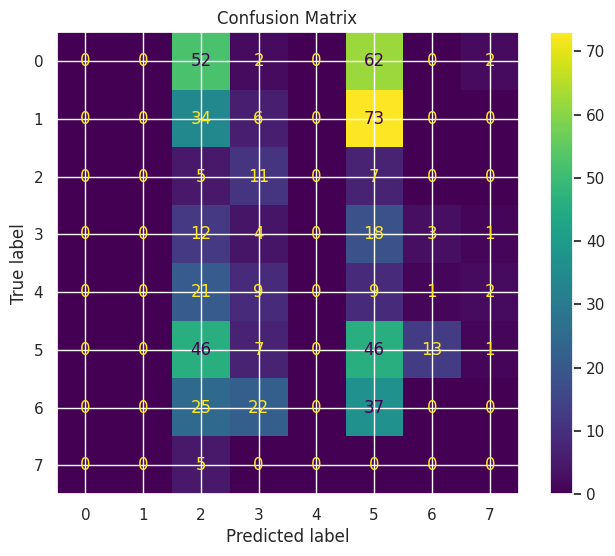

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam
------------------------------
TRAIN
Accuracy: 0.6533
Precision: 0.6796
Recall: 0.6533
F1: 0.6551
Kappa: 0.5771
Error Rate: 0.3467

TEST
Accuracy: 0.0728
Precision: 0.0746
Recall: 0.0728
F1: 0.0357
Kappa: 0.0234
Error Rate: 0.9272
Gap (overfitting): 0.5806

CV
Mean: 0.5384
Std: 0.0924
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



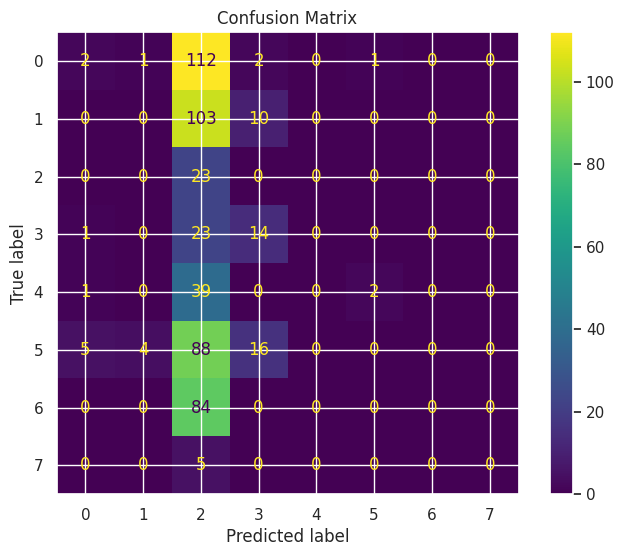

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_sgd_momentum
------------------------------
TRAIN
Accuracy: 0.4163
Precision: 0.4558
Recall: 0.4163
F1: 0.3822
Kappa: 0.2740
Error Rate: 0.5837

TEST
Accuracy: 0.2090
Precision: 0.1980
Recall: 0.2090
F1: 0.1442
Kappa: 0.0771
Error Rate: 0.7910
Gap (overfitting): 0.2074

CV
Mean: 0.2611
Std: 0.0247
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



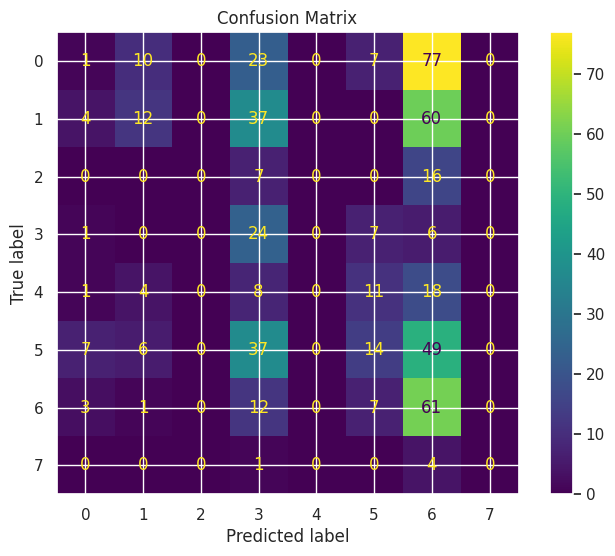

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: M


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_tanh_adam
------------------------------
TRAIN
Accuracy: 0.5749
Precision: 0.5971
Recall: 0.5749
F1: 0.5757
Kappa: 0.4814
Error Rate: 0.4251

TEST
Accuracy: 0.0112
Precision: 0.2109
Recall: 0.0112
F1: 0.0039
Kappa: -0.0029
Error Rate: 0.9888
Gap (overfitting): 0.5637

CV
Mean: 0.4627
Std: 0.0923
------------------------------
Model params:
{'activation': 'tanh', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



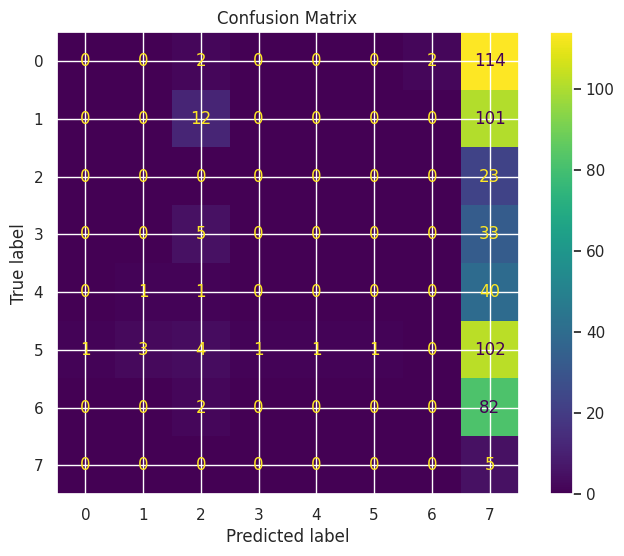

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam_lowLR
------------------------------
TRAIN
Accuracy: 0.4371
Precision: 0.4793
Recall: 0.4371
F1: 0.4087
Kappa: 0.2996
Error Rate: 0.5629

TEST
Accuracy: 0.1940
Precision: 0.2379
Recall: 0.1940
F1: 0.1273
Kappa: 0.0482
Error Rate: 0.8060
Gap (overfitting): 0.2431

CV
Mean: 0.4398
Std: 0.0905
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



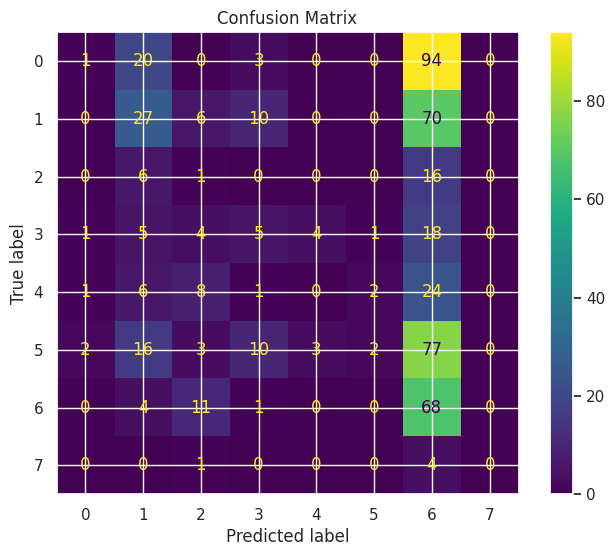

In [4]:

models = {}
# BASE
models['MLP_lbfgs_30'] = MLPClassifier(
    solver='lbfgs',
    alpha=1e-5,
    hidden_layer_sizes=(30,),
    random_state=42,
    max_iter=500
)

# relu + adam
models['MLP_relu_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)



# relu + sgd + momentum
models['MLP_relu_sgd_momentum'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    momentum=0.9,
    random_state=42,
    max_iter=500
)

# tanh + adam
models['MLP_tanh_adam'] = MLPClassifier(
    solver='adam',
    activation='tanh',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)

# relu + adam + learning rate menor
models['MLP_relu_adam_lowLR'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

main(models, "teste_combinacoes")

/tmp/ipykernel_3949/173336096.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to co


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam_lowLR_30
------------------------------
TRAIN
Accuracy: 0.4075
Precision: 0.4652
Recall: 0.4075
F1: 0.3723
Kappa: 0.2578
Error Rate: 0.5925

TEST
Accuracy: 0.2369
Precision: 0.1864
Recall: 0.2369
F1: 0.1936
Kappa: 0.0468
Error Rate: 0.7631
Gap (overfitting): 0.1706

CV
Mean: 0.3832
Std: 0.0643
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



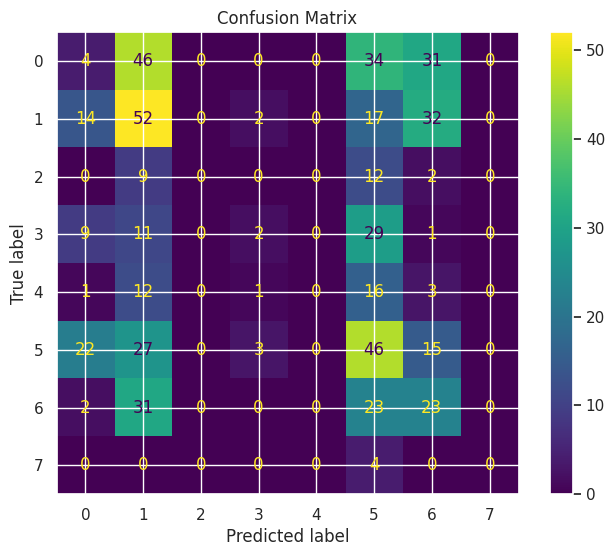

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam_lowLR_50
------------------------------
TRAIN
Accuracy: 0.4468
Precision: 0.4787
Recall: 0.4468
F1: 0.4117
Kappa: 0.3102
Error Rate: 0.5532

TEST
Accuracy: 0.1437
Precision: 0.2251
Recall: 0.1437
F1: 0.1246
Kappa: 0.0282
Error Rate: 0.8563
Gap (overfitting): 0.3031

CV
Mean: 0.4403
Std: 0.1050
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



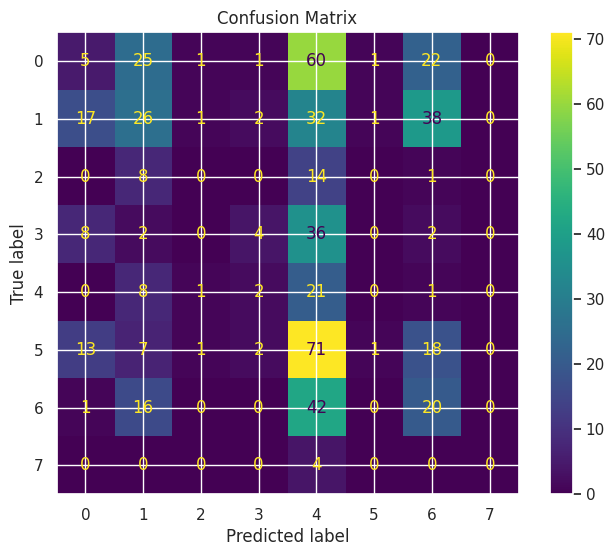

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam_lowLR_50_25
------------------------------
TRAIN
Accuracy: 0.4820
Precision: 0.5201
Recall: 0.4820
F1: 0.4559
Kappa: 0.3558
Error Rate: 0.5180

TEST
Accuracy: 0.1157
Precision: 0.2195
Recall: 0.1157
F1: 0.0932
Kappa: 0.0227
Error Rate: 0.8843
Gap (overfitting): 0.3663

CV
Mean: 0.4538
Std: 0.1071
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



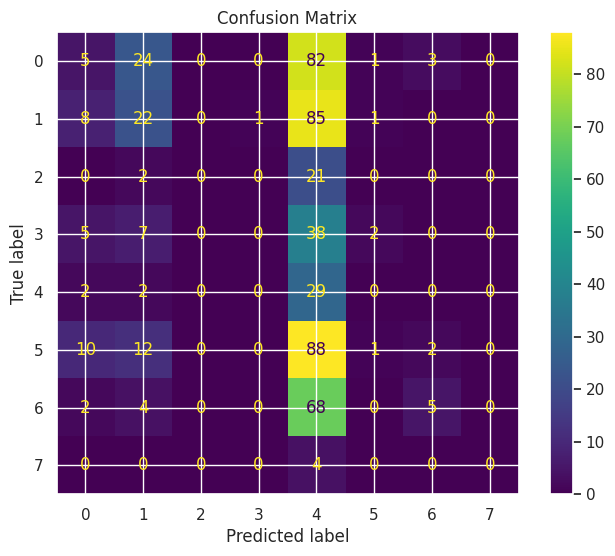

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam_lowLR_reg1e3
------------------------------
TRAIN
Accuracy: 0.4468
Precision: 0.4776
Recall: 0.4468
F1: 0.4116
Kappa: 0.3102
Error Rate: 0.5532

TEST
Accuracy: 0.1418
Precision: 0.2056
Recall: 0.1418
F1: 0.1226
Kappa: 0.0260
Error Rate: 0.8582
Gap (overfitting): 0.3050

CV
Mean: 0.4398
Std: 0.1046
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



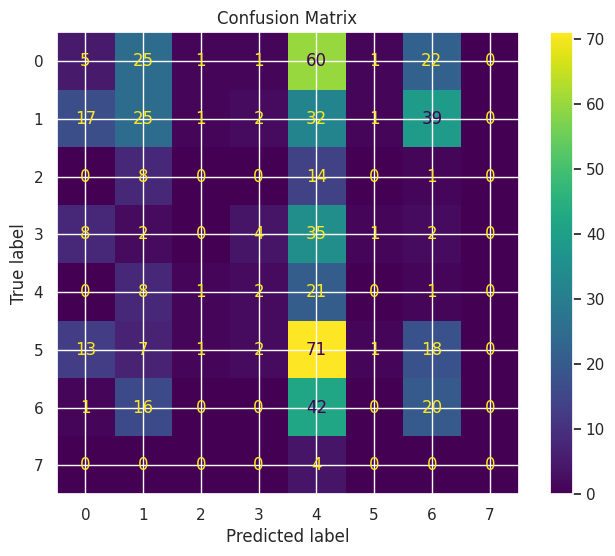

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_adam_lowLR_reg5e3
------------------------------
TRAIN
Accuracy: 0.4468
Precision: 0.4776
Recall: 0.4468
F1: 0.4116
Kappa: 0.3102
Error Rate: 0.5532

TEST
Accuracy: 0.1399
Precision: 0.2050
Recall: 0.1399
F1: 0.1218
Kappa: 0.0234
Error Rate: 0.8601
Gap (overfitting): 0.3068

CV
Mean: 0.4398
Std: 0.1046
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.005, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



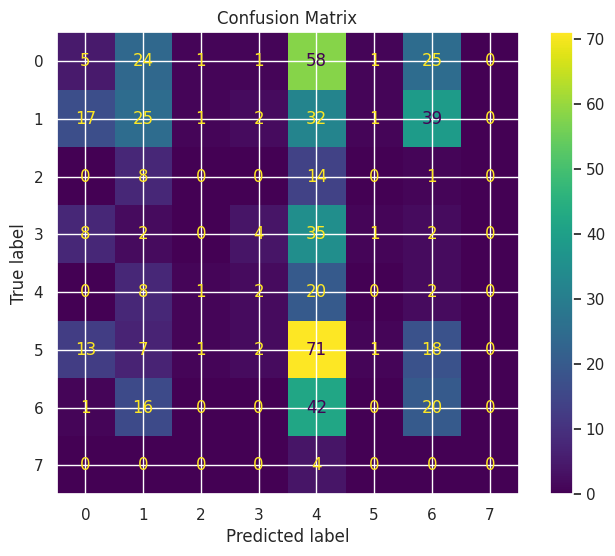

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_sgd_30
------------------------------
TRAIN
Accuracy: 0.4091
Precision: 0.3805
Recall: 0.4091
F1: 0.3696
Kappa: 0.2611
Error Rate: 0.5909

TEST
Accuracy: 0.2146
Precision: 0.2023
Recall: 0.2146
F1: 0.1738
Kappa: 0.0490
Error Rate: 0.7854
Gap (overfitting): 0.1946

CV
Mean: 0.2224
Std: 0.0042
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



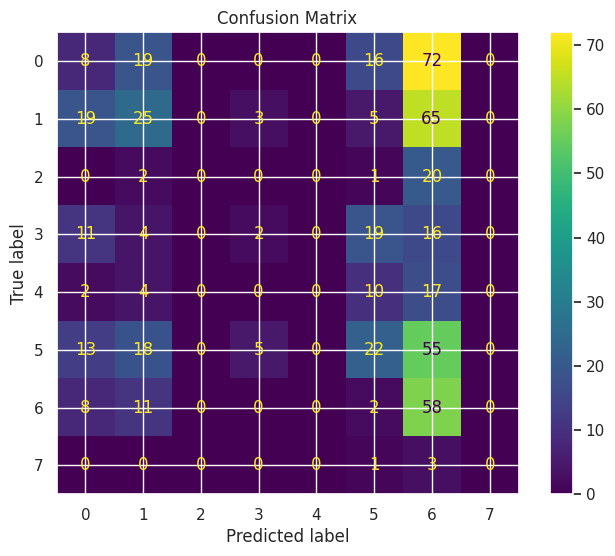

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_sgd_50
------------------------------
TRAIN
Accuracy: 0.4259
Precision: 0.5075
Recall: 0.4259
F1: 0.3826
Kappa: 0.2797
Error Rate: 0.5741

TEST
Accuracy: 0.1213
Precision: 0.1908
Recall: 0.1213
F1: 0.1112
Kappa: -0.0060
Error Rate: 0.8787
Gap (overfitting): 0.3047

CV
Mean: 0.2426
Std: 0.0490
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



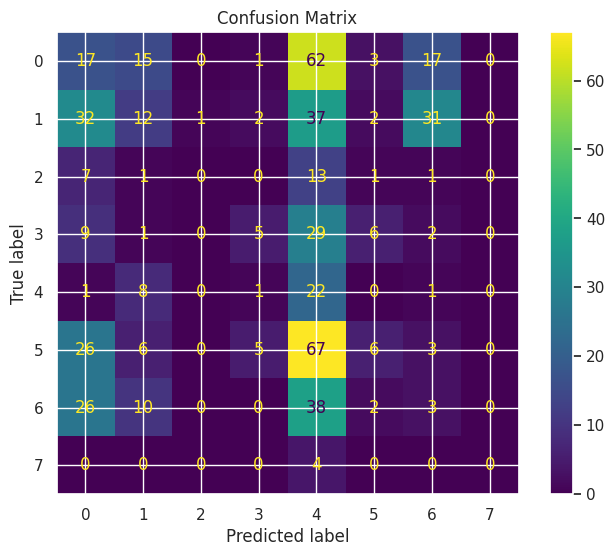

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_relu_sgd_adaptive
------------------------------
TRAIN
Accuracy: 0.4716
Precision: 0.5049
Recall: 0.4716
F1: 0.4478
Kappa: 0.3431
Error Rate: 0.5284

TEST
Accuracy: 0.1511
Precision: 0.3354
Recall: 0.1511
F1: 0.1363
Kappa: 0.0535
Error Rate: 0.8489
Gap (overfitting): 0.3205

CV
Mean: 0.2717
Std: 0.0411
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.95, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



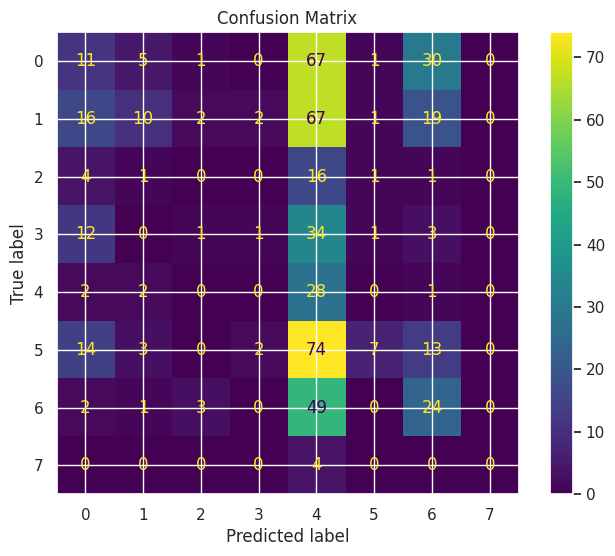

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: Conv


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_lbfgs_30
------------------------------
TRAIN
Accuracy: 0.8327
Precision: 0.8370
Recall: 0.8327
F1: 0.8313
Kappa: 0.7965
Error Rate: 0.1673

TEST
Accuracy: 0.2519
Precision: 0.1515
Recall: 0.2519
F1: 0.1609
Kappa: 0.0514
Error Rate: 0.7481
Gap (overfitting): 0.5808

CV
Mean: 0.4039
Std: 0.0889
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'lbfgs', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



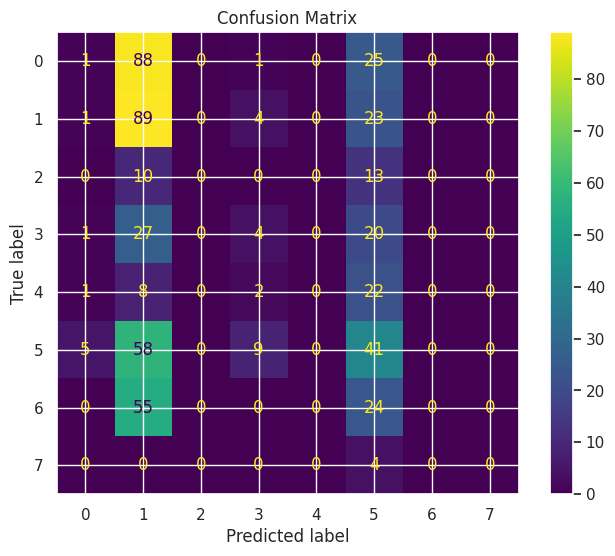

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: Conv


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_lbfgs_50
------------------------------
TRAIN
Accuracy: 0.8639
Precision: 0.8686
Recall: 0.8639
F1: 0.8629
Kappa: 0.8344
Error Rate: 0.1361

TEST
Accuracy: 0.2015
Precision: 0.0657
Recall: 0.2015
F1: 0.0771
Kappa: -0.0085
Error Rate: 0.7985
Gap (overfitting): 0.6624

CV
Mean: 0.5020
Std: 0.1288
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 1000, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'lbfgs', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



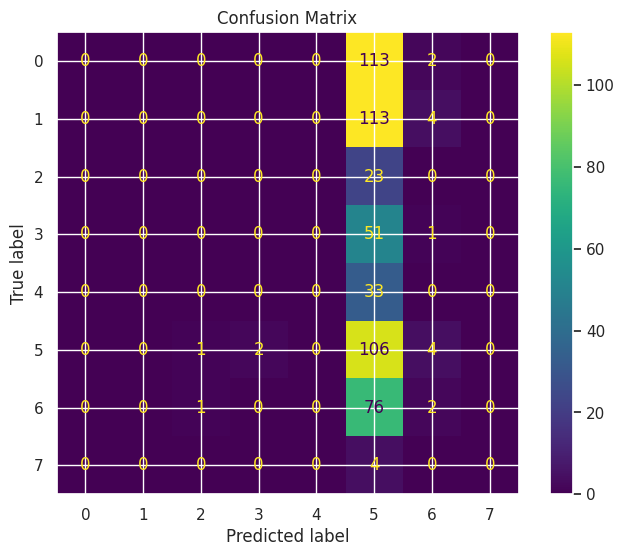

In [5]:
models_f1 = {}
models_f1['MLP_relu_adam_lowLR_30'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_adam_lowLR_50'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_adam_lowLR_50_25'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_adam_lowLR_reg1e3'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-3,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_adam_lowLR_reg5e3'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=5e-3,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_sgd_30'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    momentum=0.9,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_sgd_50'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-5,
    momentum=0.9,
    random_state=42,
    max_iter=500
)

models_f1['MLP_relu_sgd_adaptive'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-3,
    momentum=0.95,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f1['MLP_lbfgs_30'] = MLPClassifier(
    solver='lbfgs',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)

models_f1['MLP_lbfgs_50'] = MLPClassifier(
    solver='lbfgs',
    hidden_layer_sizes=(50,),
    alpha=1e-3,
    random_state=42,
    max_iter=1000
)

main(models_f1, "fase_1")

/tmp/ipykernel_3949/173336096.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to co


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_solver_adam
------------------------------
TRAIN
Accuracy: 0.4660
Precision: 0.4792
Recall: 0.4660
F1: 0.4342
Kappa: 0.3377
Error Rate: 0.5340

TEST
Accuracy: 0.2463
Precision: 0.2607
Recall: 0.2463
F1: 0.1812
Kappa: 0.0846
Error Rate: 0.7537
Gap (overfitting): 0.2197

CV
Mean: 0.4611
Std: 0.0685
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



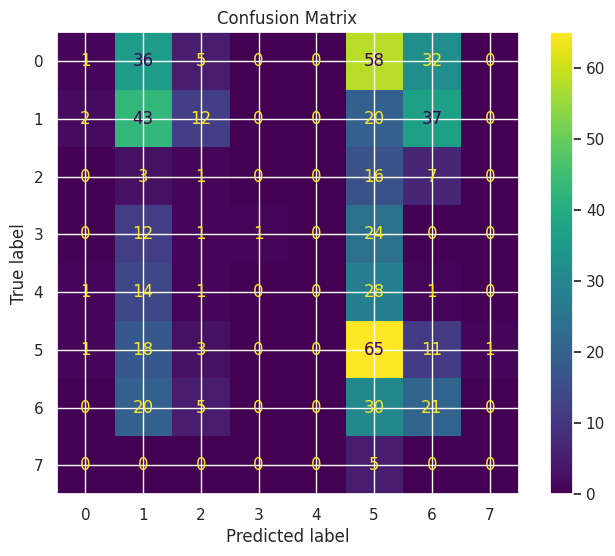

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_solver_sgd
------------------------------
TRAIN
Accuracy: 0.2914
Precision: 0.2309
Recall: 0.2914
F1: 0.2181
Kappa: 0.0934
Error Rate: 0.7086

TEST
Accuracy: 0.2575
Precision: 0.1793
Recall: 0.2575
F1: 0.1710
Kappa: 0.0735
Error Rate: 0.7425
Gap (overfitting): 0.0340

CV
Mean: 0.3658
Std: 0.0348
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



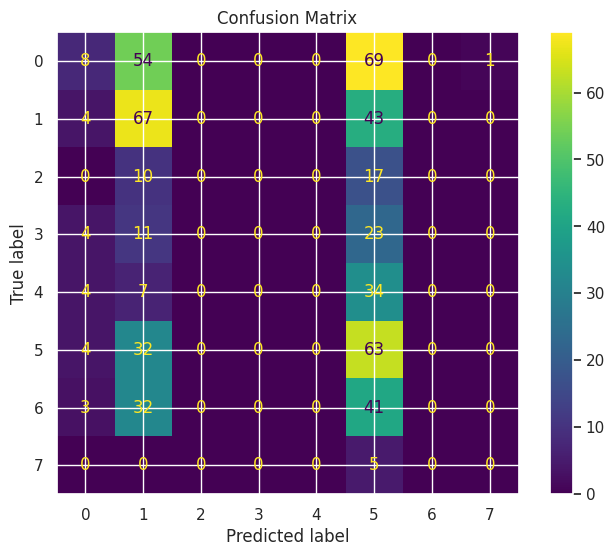

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: Conv


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_solver_lbfgs
------------------------------
TRAIN
Accuracy: 0.9680
Precision: 0.9682
Recall: 0.9680
F1: 0.9680
Kappa: 0.9613
Error Rate: 0.0320

TEST
Accuracy: 0.1922
Precision: 0.4191
Recall: 0.1922
F1: 0.1333
Kappa: 0.0545
Error Rate: 0.8078
Gap (overfitting): 0.7758

CV
Mean: 0.5008
Std: 0.0813
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'lbfgs', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



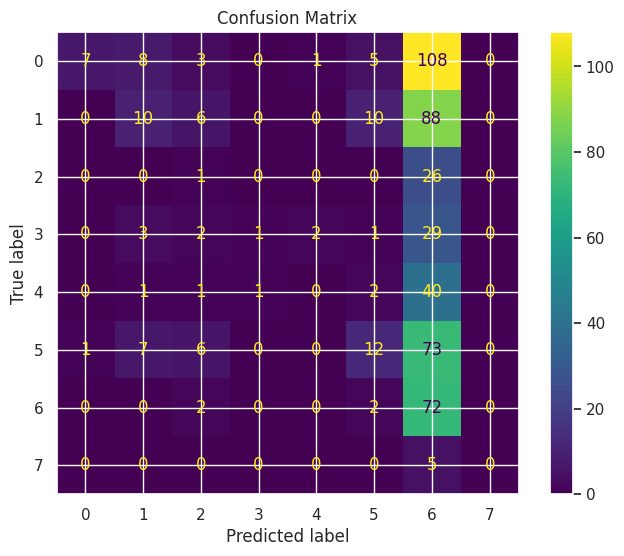

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_activation_relu
------------------------------
TRAIN
Accuracy: 0.4660
Precision: 0.4792
Recall: 0.4660
F1: 0.4342
Kappa: 0.3377
Error Rate: 0.5340

TEST
Accuracy: 0.2463
Precision: 0.2607
Recall: 0.2463
F1: 0.1812
Kappa: 0.0846
Error Rate: 0.7537
Gap (overfitting): 0.2197

CV
Mean: 0.4611
Std: 0.0685
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



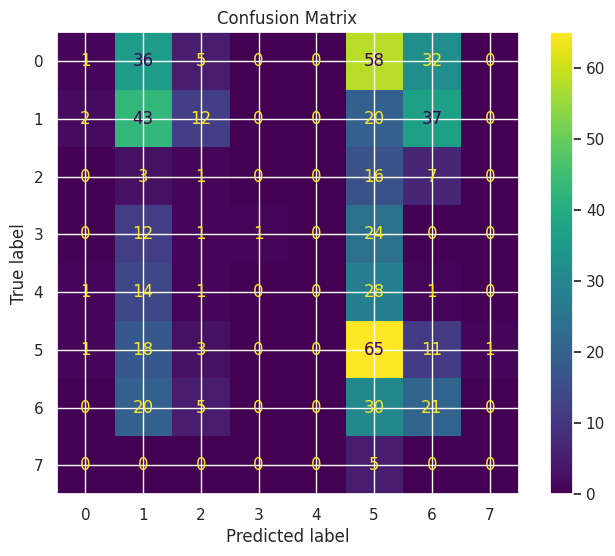

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_activation_tanh
------------------------------
TRAIN
Accuracy: 0.4764
Precision: 0.4866
Recall: 0.4764
F1: 0.4460
Kappa: 0.3517
Error Rate: 0.5236

TEST
Accuracy: 0.1698
Precision: 0.2096
Recall: 0.1698
F1: 0.1443
Kappa: 0.0438
Error Rate: 0.8302
Gap (overfitting): 0.3066

CV
Mean: 0.3513
Std: 0.0363
------------------------------
Model params:
{'activation': 'tanh', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



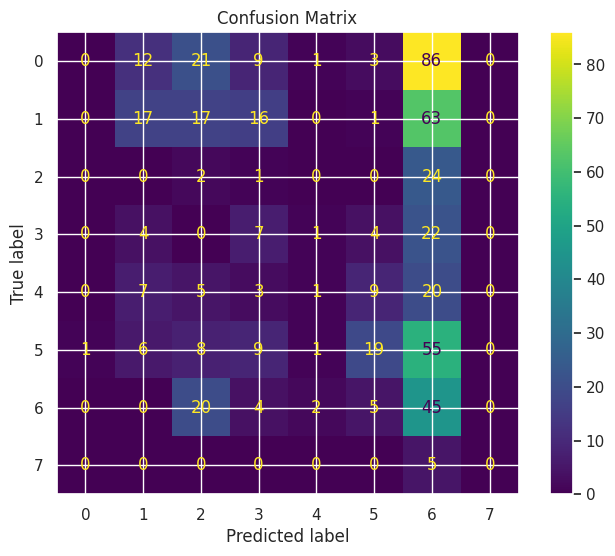

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_activation_logistic
------------------------------
TRAIN
Accuracy: 0.2914
Precision: 0.2217
Recall: 0.2914
F1: 0.2178
Kappa: 0.0933
Error Rate: 0.7086

TEST
Accuracy: 0.2015
Precision: 0.1745
Recall: 0.2015
F1: 0.1480
Kappa: 0.0371
Error Rate: 0.7985
Gap (overfitting): 0.0899

CV
Mean: 0.4157
Std: 0.0288
------------------------------
Model params:
{'activation': 'logistic', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



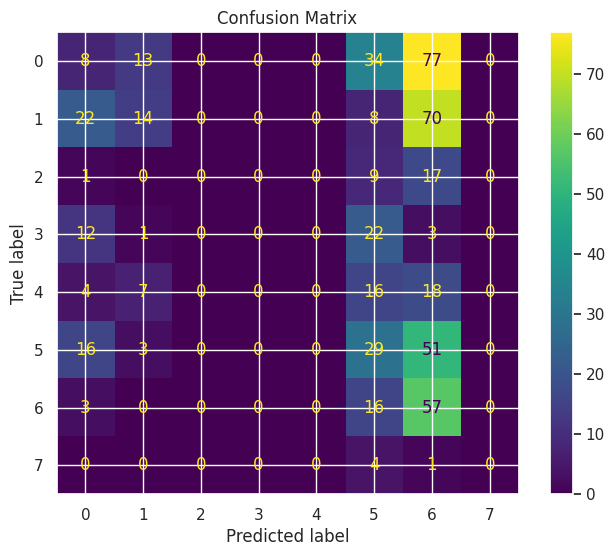

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_arch_10
------------------------------
TRAIN
Accuracy: 0.3963
Precision: 0.2961
Recall: 0.3963
F1: 0.3278
Kappa: 0.2416
Error Rate: 0.6037

TEST
Accuracy: 0.1101
Precision: 0.1404
Recall: 0.1101
F1: 0.0742
Kappa: 0.0058
Error Rate: 0.8899
Gap (overfitting): 0.2862

CV
Mean: 0.1905
Std: 0.0050
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (10,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



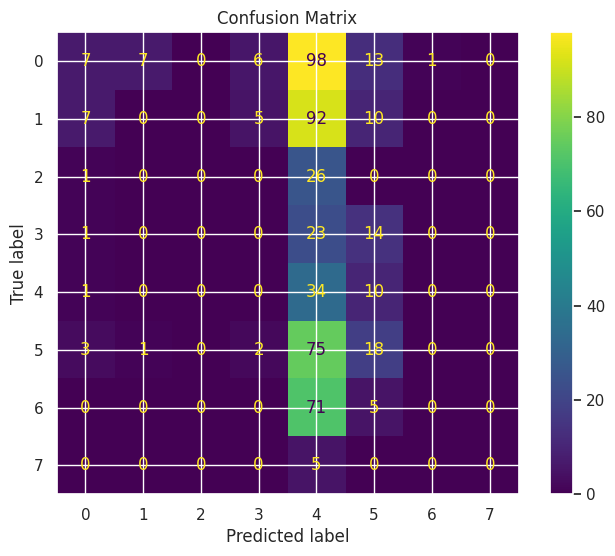

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_arch_30
------------------------------
TRAIN
Accuracy: 0.4660
Precision: 0.4792
Recall: 0.4660
F1: 0.4342
Kappa: 0.3377
Error Rate: 0.5340

TEST
Accuracy: 0.2463
Precision: 0.2607
Recall: 0.2463
F1: 0.1812
Kappa: 0.0846
Error Rate: 0.7537
Gap (overfitting): 0.2197

CV
Mean: 0.4611
Std: 0.0685
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



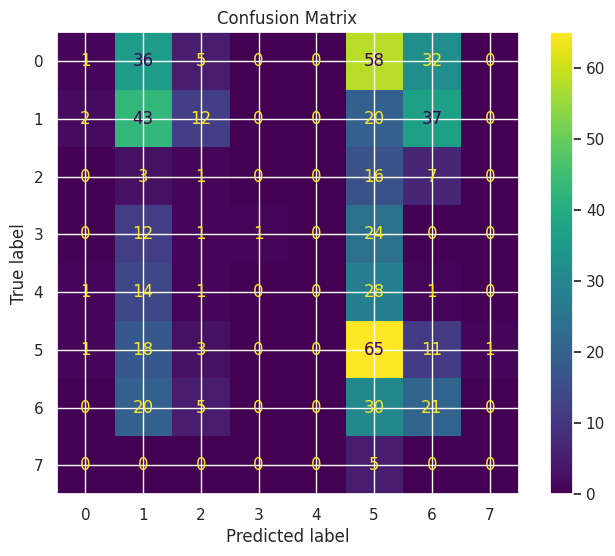

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_arch_50
------------------------------
TRAIN
Accuracy: 0.4948
Precision: 0.5130
Recall: 0.4948
F1: 0.4570
Kappa: 0.3728
Error Rate: 0.5052

TEST
Accuracy: 0.1903
Precision: 0.3267
Recall: 0.1903
F1: 0.1139
Kappa: 0.0159
Error Rate: 0.8097
Gap (overfitting): 0.3045

CV
Mean: 0.4717
Std: 0.0629
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



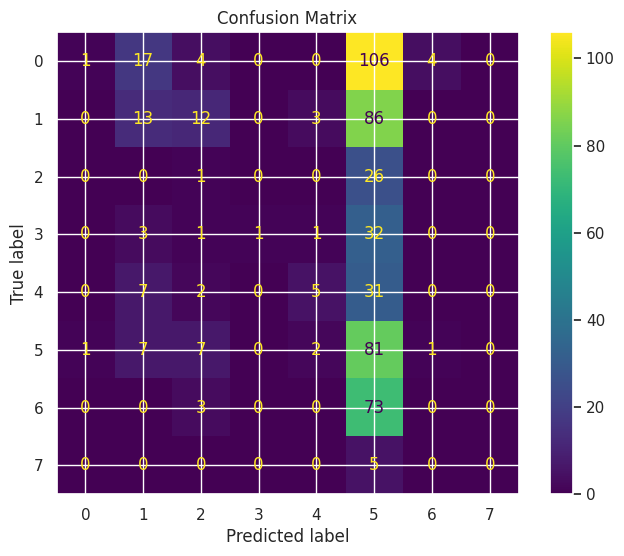

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_arch_50_25
------------------------------
TRAIN
Accuracy: 0.5404
Precision: 0.5969
Recall: 0.5404
F1: 0.5227
Kappa: 0.4335
Error Rate: 0.4596

TEST
Accuracy: 0.1194
Precision: 0.4562
Recall: 0.1194
F1: 0.0807
Kappa: 0.0333
Error Rate: 0.8806
Gap (overfitting): 0.4210

CV
Mean: 0.4975
Std: 0.0856
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



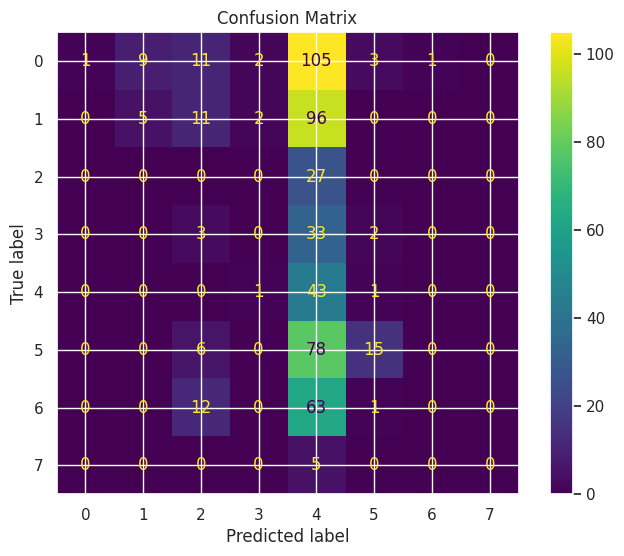

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_alpha_1e-6
------------------------------
TRAIN
Accuracy: 0.4660
Precision: 0.4792
Recall: 0.4660
F1: 0.4342
Kappa: 0.3377
Error Rate: 0.5340

TEST
Accuracy: 0.2369
Precision: 0.2398
Recall: 0.2369
F1: 0.1741
Kappa: 0.0719
Error Rate: 0.7631
Gap (overfitting): 0.2290

CV
Mean: 0.4633
Std: 0.0690
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



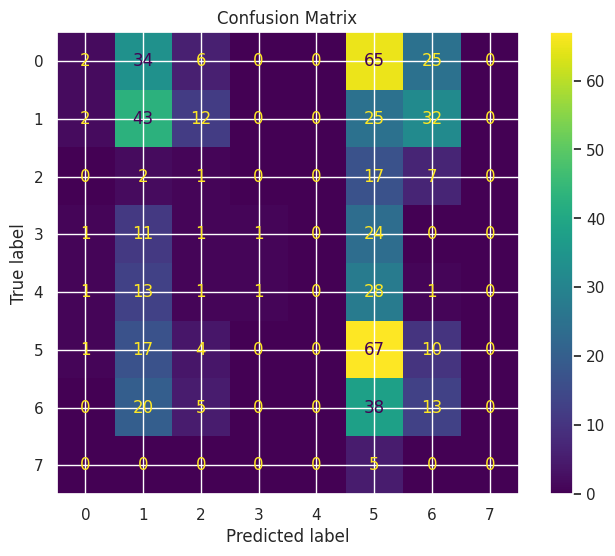

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_alpha_1e-5
------------------------------
TRAIN
Accuracy: 0.4660
Precision: 0.4792
Recall: 0.4660
F1: 0.4342
Kappa: 0.3377
Error Rate: 0.5340

TEST
Accuracy: 0.2463
Precision: 0.2607
Recall: 0.2463
F1: 0.1812
Kappa: 0.0846
Error Rate: 0.7537
Gap (overfitting): 0.2197

CV
Mean: 0.4611
Std: 0.0685
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



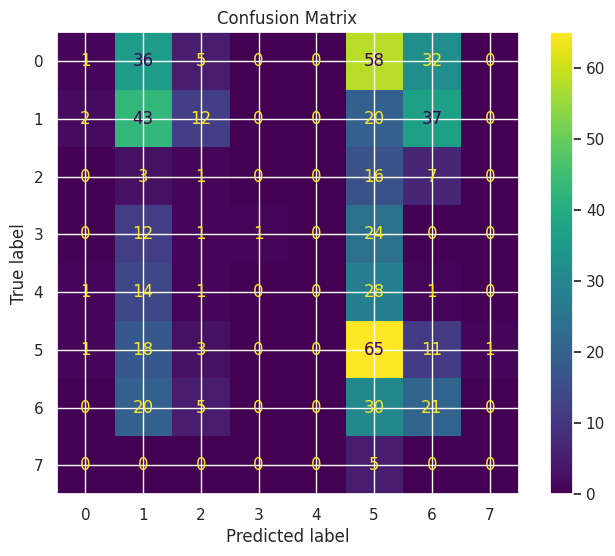

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_alpha_1e-4
------------------------------
TRAIN
Accuracy: 0.4660
Precision: 0.4792
Recall: 0.4660
F1: 0.4342
Kappa: 0.3377
Error Rate: 0.5340

TEST
Accuracy: 0.2444
Precision: 0.2927
Recall: 0.2444
F1: 0.1832
Kappa: 0.0829
Error Rate: 0.7556
Gap (overfitting): 0.2216

CV
Mean: 0.4599
Std: 0.0691
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



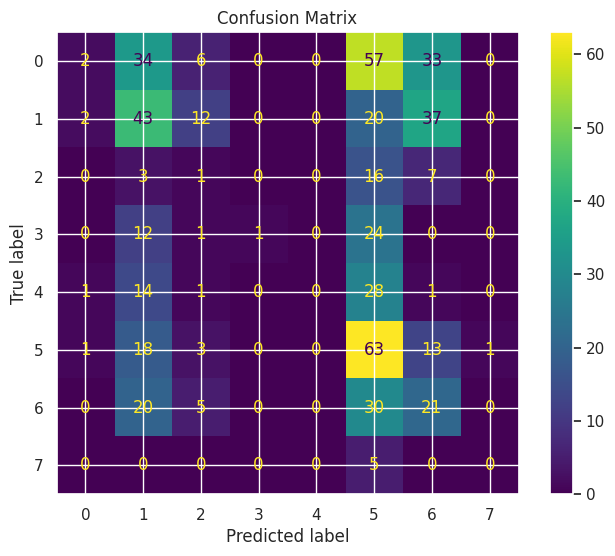

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: MLP_alpha_1e-3
------------------------------
TRAIN
Accuracy: 0.4636
Precision: 0.4812
Recall: 0.4636
F1: 0.4299
Kappa: 0.3343
Error Rate: 0.5364

TEST
Accuracy: 0.2369
Precision: 0.2907
Recall: 0.2369
F1: 0.1806
Kappa: 0.0748
Error Rate: 0.7631
Gap (overfitting): 0.2266

CV
Mean: 0.4605
Std: 0.0690
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



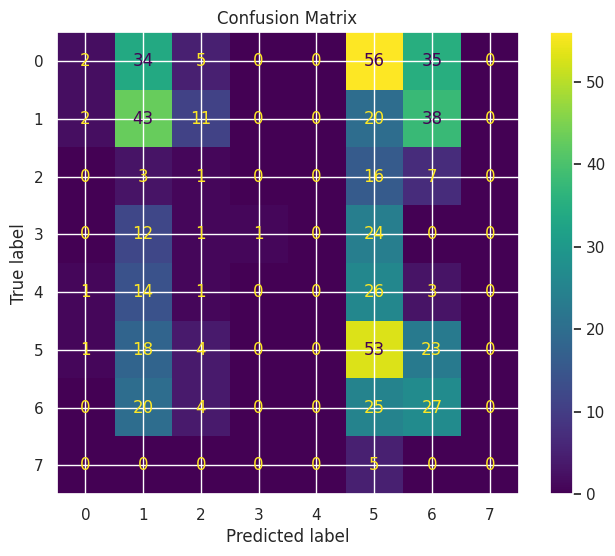

In [6]:
models_f2 = {}
#OTIMIZADOR
models_f2['MLP_solver_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_solver_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    momentum=0.9,
    random_state=42,
    max_iter=500
)

models_f2['MLP_solver_lbfgs'] = MLPClassifier(
    solver='lbfgs',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)
#ATIVAÇÃO
models_f2['MLP_activation_relu'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_activation_tanh'] = MLPClassifier(
    solver='adam',
    activation='tanh',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_activation_logistic'] = MLPClassifier(
    solver='adam',
    activation='logistic',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)
#ARQAUITTRUA
models_f2['MLP_arch_10'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(10,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_arch_30'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_arch_50'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_arch_50_25'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)
#REGULARIZCAO
models_f2['MLP_alpha_1e-6'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-6,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_alpha_1e-5'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_alpha_1e-4'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-4,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f2['MLP_alpha_1e-3'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-3,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)
main(models_f2, "fase_2")
#FASE 2 PEGAS OS MELHROES DAQUI
#FASE 3 MUDA SEMNTE, MUDA NUMERO DE TIRACOES

/tmp/ipykernel_3949/173336096.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to co


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_alpha1e-4_adam
------------------------------
TRAIN
Accuracy: 0.4211
Precision: 0.3721
Recall: 0.4211
F1: 0.3834
Kappa: 0.2781
Error Rate: 0.5789

TEST
Accuracy: 0.2071
Precision: 0.2020
Recall: 0.2071
F1: 0.1205
Kappa: 0.0324
Error Rate: 0.7929
Gap (overfitting): 0.2140

CV
Mean: 0.4039
Std: 0.1002
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



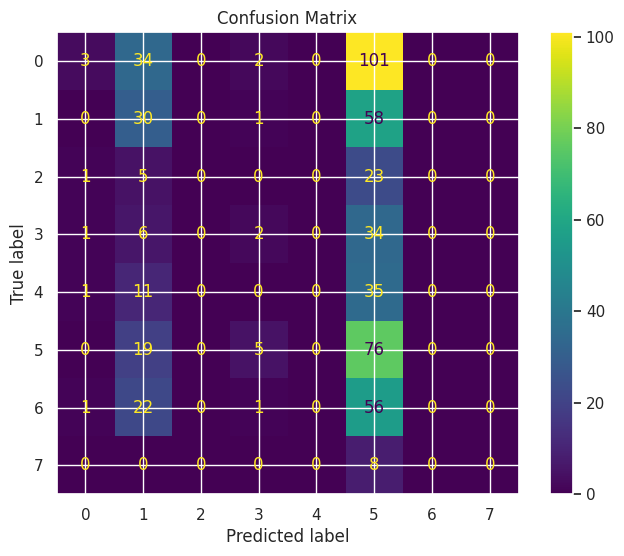

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_alpha1e-6_adam
------------------------------
TRAIN
Accuracy: 0.4219
Precision: 0.3728
Recall: 0.4219
F1: 0.3842
Kappa: 0.2791
Error Rate: 0.5781

TEST
Accuracy: 0.2052
Precision: 0.1861
Recall: 0.2052
F1: 0.1192
Kappa: 0.0302
Error Rate: 0.7948
Gap (overfitting): 0.2167

CV
Mean: 0.4039
Std: 0.0988
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



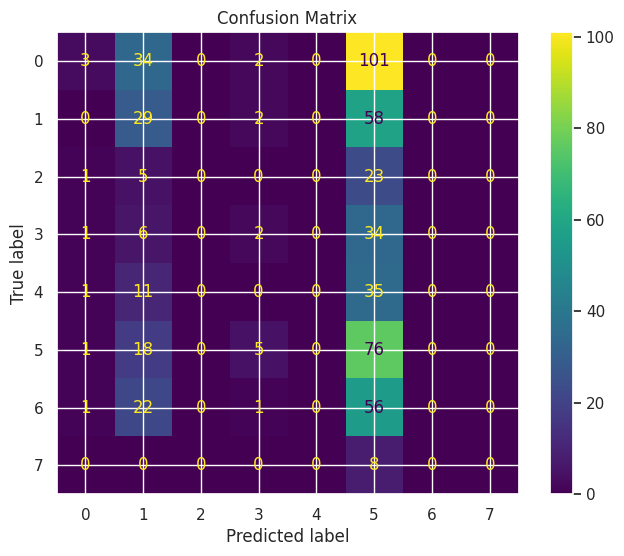

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_alpha1e-4_adam
------------------------------
TRAIN
Accuracy: 0.4836
Precision: 0.4937
Recall: 0.4836
F1: 0.4599
Kappa: 0.3573
Error Rate: 0.5164

TEST
Accuracy: 0.2295
Precision: 0.2355
Recall: 0.2295
F1: 0.1811
Kappa: 0.0607
Error Rate: 0.7705
Gap (overfitting): 0.2541

CV
Mean: 0.4863
Std: 0.1110
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



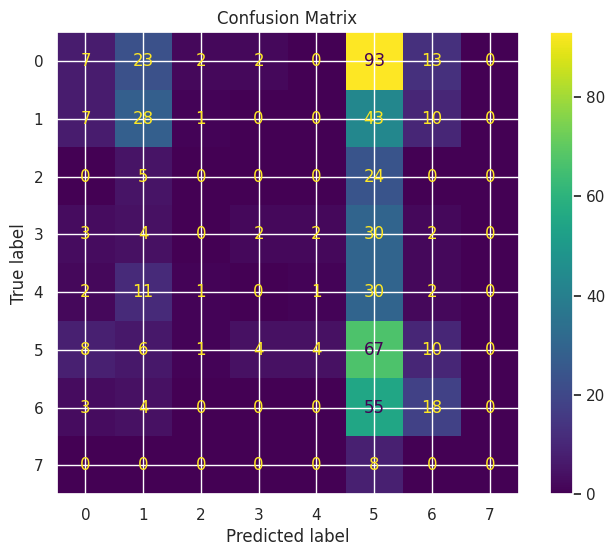

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_alpha1e-6_adam
------------------------------
TRAIN
Accuracy: 0.4884
Precision: 0.4958
Recall: 0.4884
F1: 0.4627
Kappa: 0.3637
Error Rate: 0.5116

TEST
Accuracy: 0.2388
Precision: 0.2448
Recall: 0.2388
F1: 0.1942
Kappa: 0.0761
Error Rate: 0.7612
Gap (overfitting): 0.2496

CV
Mean: 0.4874
Std: 0.1092
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



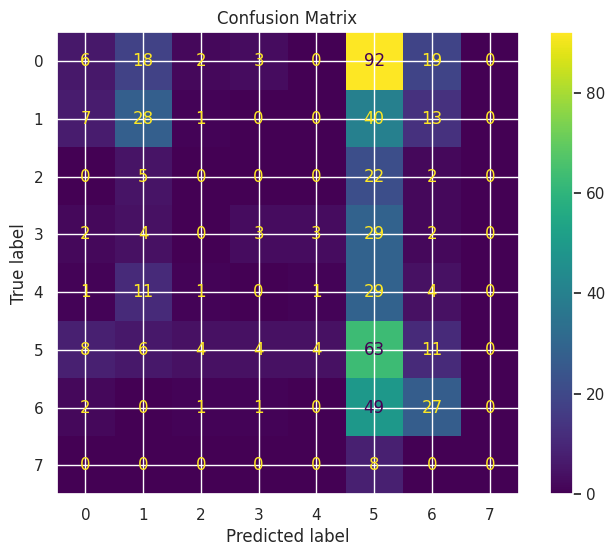

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_25_alpha1e-4_adam
------------------------------
TRAIN
Accuracy: 0.5300
Precision: 0.5655
Recall: 0.5300
F1: 0.5089
Kappa: 0.4167
Error Rate: 0.4700

TEST
Accuracy: 0.1549
Precision: 0.2474
Recall: 0.1549
F1: 0.1146
Kappa: 0.0562
Error Rate: 0.8451
Gap (overfitting): 0.3752

CV
Mean: 0.4678
Std: 0.0849
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



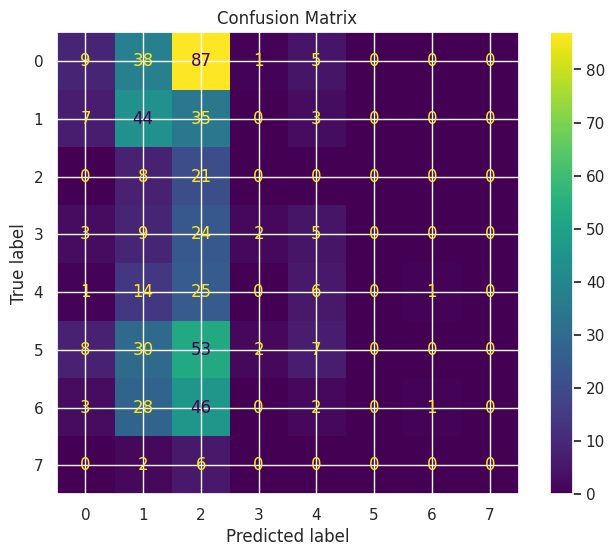

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_25_alpha1e-6_adam
------------------------------
TRAIN
Accuracy: 0.5388
Precision: 0.5758
Recall: 0.5388
F1: 0.5172
Kappa: 0.4270
Error Rate: 0.4612

TEST
Accuracy: 0.1511
Precision: 0.4183
Recall: 0.1511
F1: 0.1224
Kappa: 0.0603
Error Rate: 0.8489
Gap (overfitting): 0.3877

CV
Mean: 0.4639
Std: 0.0876
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.0001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



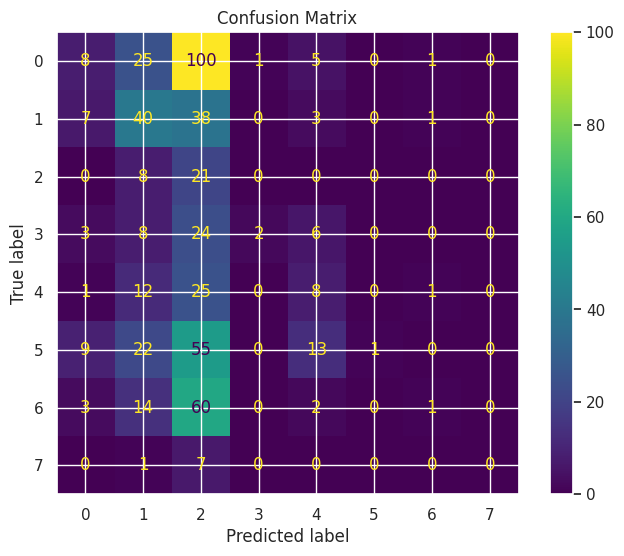

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_50_alpha1e-4_sgd
------------------------------
TRAIN
Accuracy: 0.4404
Precision: 0.3936
Recall: 0.4404
F1: 0.4035
Kappa: 0.3020
Error Rate: 0.5596

TEST
Accuracy: 0.2295
Precision: 0.2275
Recall: 0.2295
F1: 0.1889
Kappa: 0.0568
Error Rate: 0.7705
Gap (overfitting): 0.2109

CV
Mean: 0.2359
Std: 0.0080
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



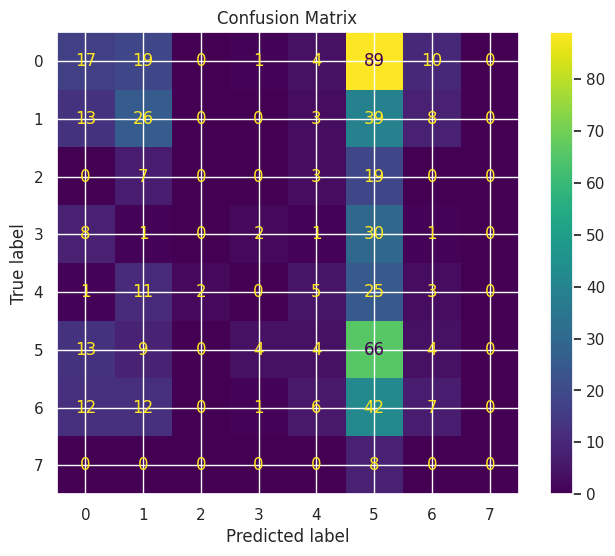

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F2_30_alpha1e-4_sgd
------------------------------
TRAIN
Accuracy: 0.4219
Precision: 0.3741
Recall: 0.4219
F1: 0.3840
Kappa: 0.2791
Error Rate: 0.5781

TEST
Accuracy: 0.2164
Precision: 0.1571
Recall: 0.2164
F1: 0.1477
Kappa: 0.0286
Error Rate: 0.7836
Gap (overfitting): 0.2055

CV
Mean: 0.2246
Std: 0.0323
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



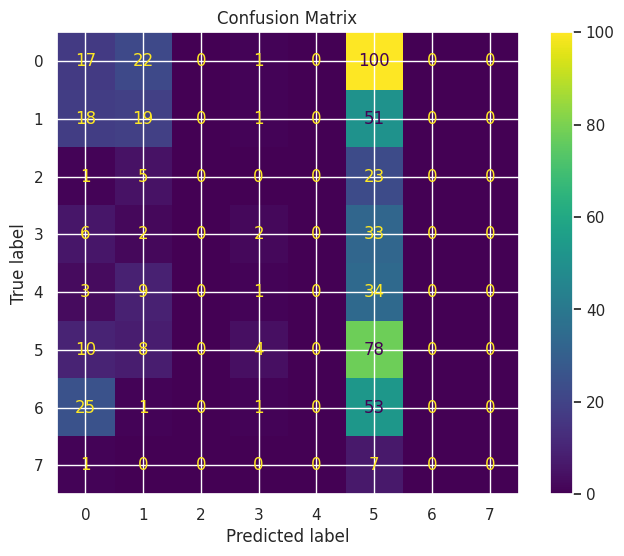

In [7]:
models_f3 = {}

# =========================
# 🔥 BASE TOP (ADAM)
# =========================

models_f3['F2_30_alpha1e-4_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-4,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f3['F2_30_alpha1e-6_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-6,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f3['F2_50_alpha1e-4_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-4,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f3['F2_50_alpha1e-6_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-6,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f3['F2_50_25_alpha1e-4_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-4,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

models_f3['F2_50_25_alpha1e-6_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-6,
    learning_rate_init=0.0001,
    random_state=42,
    max_iter=500
)

# =========================
# ⚖️ CONTROLE (SGD)
# =========================

models_f3['F2_50_alpha1e-4_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-4,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f3['F2_30_alpha1e-4_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-4,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)
main(models_f3, "fase_3")

/tmp/ipykernel_3949/173336096.py:178: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  _data_frame.replace([np.inf, -np.inf], 0, inplace=True)
/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to co


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_alpha1e-4_adam
------------------------------
TRAIN
Accuracy: 0.7454
Precision: 0.7696
Recall: 0.7454
F1: 0.7463
Kappa: 0.6889
Error Rate: 0.2546

TEST
Accuracy: 0.1604
Precision: 0.1109
Recall: 0.1604
F1: 0.0913
Kappa: -0.0283
Error Rate: 0.8396
Gap (overfitting): 0.5849

CV
Mean: 0.4056
Std: 0.0714
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



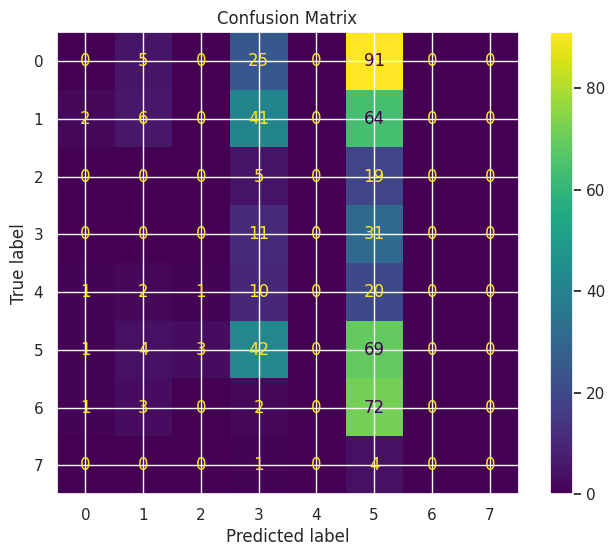

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_alpha1e-6_adam
------------------------------
TRAIN
Accuracy: 0.7318
Precision: 0.7521
Recall: 0.7318
F1: 0.7339
Kappa: 0.6722
Error Rate: 0.2682

TEST
Accuracy: 0.1903
Precision: 0.0982
Recall: 0.1903
F1: 0.0954
Kappa: -0.0107
Error Rate: 0.8097
Gap (overfitting): 0.5415

CV
Mean: 0.4050
Std: 0.0757
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



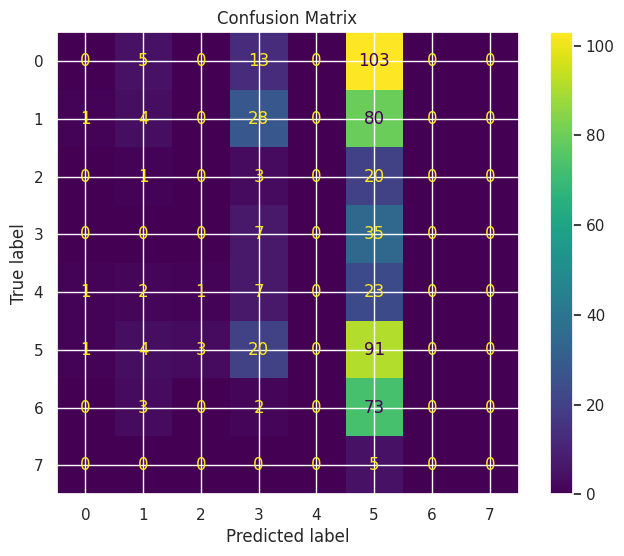

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_alpha1e-5_adam
------------------------------
TRAIN
Accuracy: 0.7238
Precision: 0.7428
Recall: 0.7238
F1: 0.7242
Kappa: 0.6625
Error Rate: 0.2762

TEST
Accuracy: 0.1959
Precision: 0.0971
Recall: 0.1959
F1: 0.0968
Kappa: -0.0071
Error Rate: 0.8041
Gap (overfitting): 0.5279

CV
Mean: 0.4034
Std: 0.0758
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



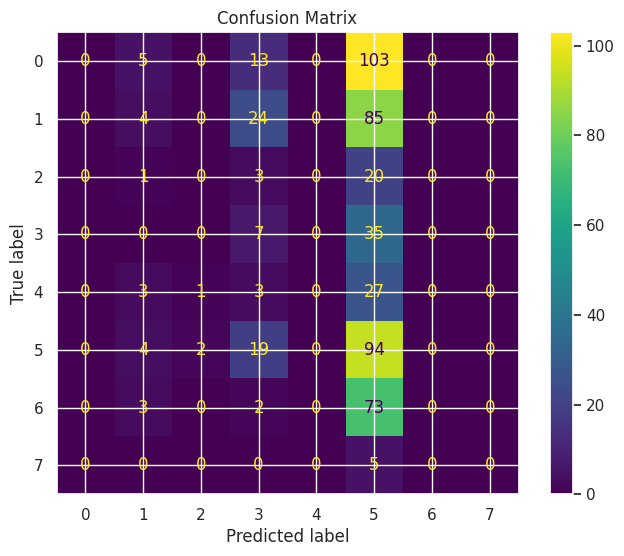

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_alpha1e-4_adam
------------------------------
TRAIN
Accuracy: 0.7710
Precision: 0.7928
Recall: 0.7710
F1: 0.7712
Kappa: 0.7200
Error Rate: 0.2290

TEST
Accuracy: 0.2090
Precision: 0.1472
Recall: 0.2090
F1: 0.0937
Kappa: -0.0050
Error Rate: 0.7910
Gap (overfitting): 0.5621

CV
Mean: 0.5518
Std: 0.1372
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



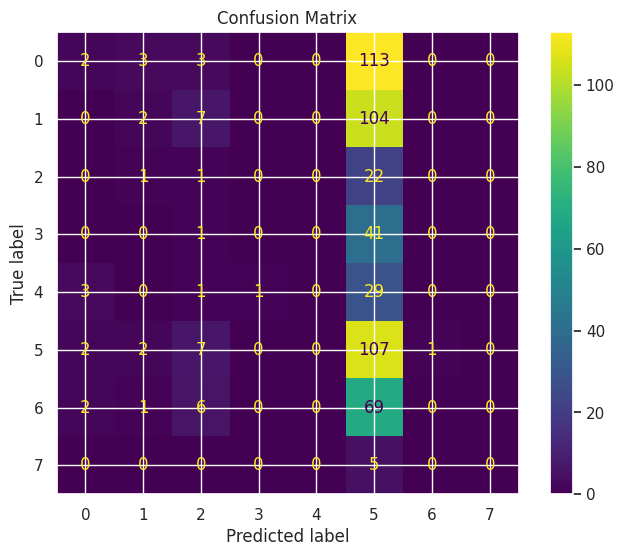

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_alpha1e-6_adam
------------------------------
TRAIN
Accuracy: 0.7622
Precision: 0.7835
Recall: 0.7622
F1: 0.7625
Kappa: 0.7092
Error Rate: 0.2378

TEST
Accuracy: 0.1847
Precision: 0.1282
Recall: 0.1847
F1: 0.0903
Kappa: -0.0116
Error Rate: 0.8153
Gap (overfitting): 0.5775

CV
Mean: 0.5440
Std: 0.1384
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



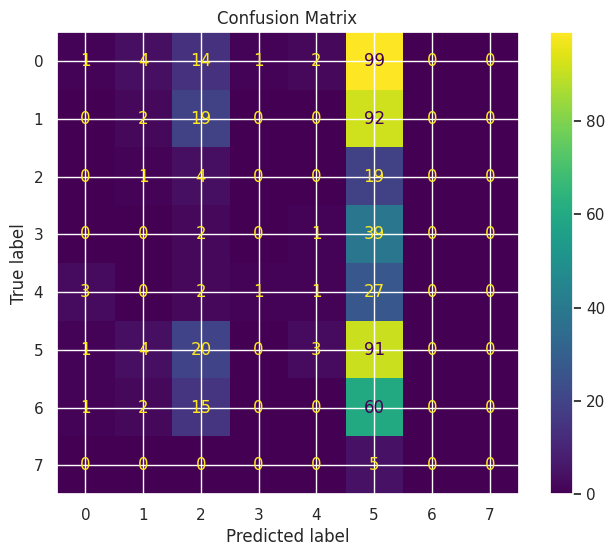

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_alpha1e-5_adam
------------------------------
TRAIN
Accuracy: 0.7646
Precision: 0.7820
Recall: 0.7646
F1: 0.7628
Kappa: 0.7123
Error Rate: 0.2354

TEST
Accuracy: 0.2052
Precision: 0.1176
Recall: 0.2052
F1: 0.0921
Kappa: -0.0024
Error Rate: 0.7948
Gap (overfitting): 0.5594

CV
Mean: 0.5485
Std: 0.1470
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



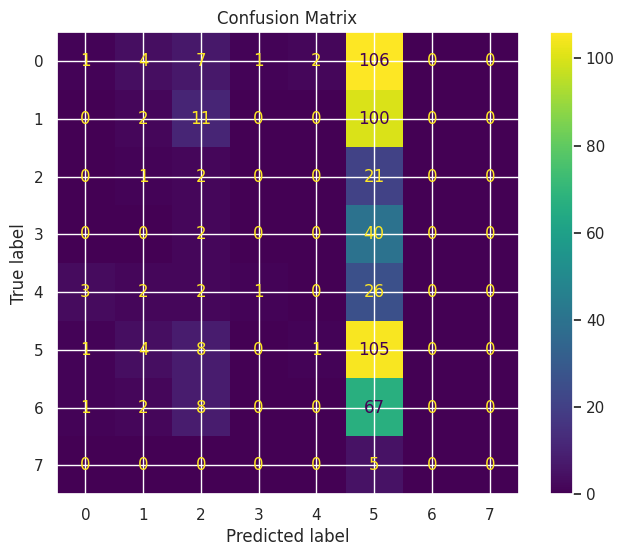

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_alpha1e-4_adam
------------------------------
TRAIN
Accuracy: 0.8751
Precision: 0.8816
Recall: 0.8751
F1: 0.8754
Kappa: 0.8480
Error Rate: 0.1249

TEST
Accuracy: 0.1940
Precision: 0.2880
Recall: 0.1940
F1: 0.0940
Kappa: -0.0040
Error Rate: 0.8060
Gap (overfitting): 0.6811

CV
Mean: 0.4560
Std: 0.1114
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



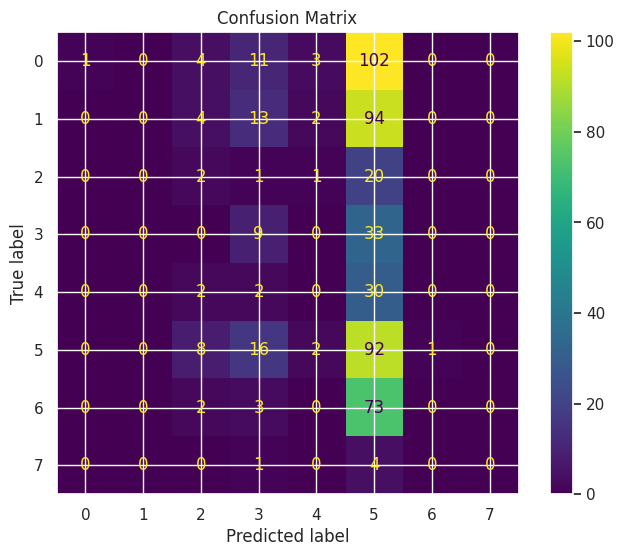

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_alpha1e-6_adam
------------------------------
TRAIN
Accuracy: 0.8751
Precision: 0.8791
Recall: 0.8751
F1: 0.8752
Kappa: 0.8481
Error Rate: 0.1249

TEST
Accuracy: 0.1996
Precision: 0.0514
Recall: 0.1996
F1: 0.0814
Kappa: -0.0050
Error Rate: 0.8004
Gap (overfitting): 0.6755

CV
Mean: 0.4599
Std: 0.0930
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



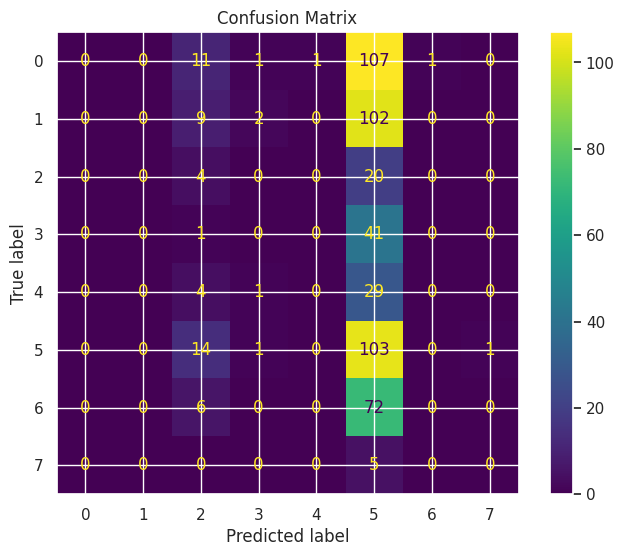

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_alpha1e-5_adam
------------------------------
TRAIN
Accuracy: 0.8767
Precision: 0.8850
Recall: 0.8767
F1: 0.8775
Kappa: 0.8499
Error Rate: 0.1233

TEST
Accuracy: 0.2034
Precision: 0.1399
Recall: 0.2034
F1: 0.0963
Kappa: 0.0032
Error Rate: 0.7966
Gap (overfitting): 0.6733

CV
Mean: 0.4768
Std: 0.1081
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'constant', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'adam', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



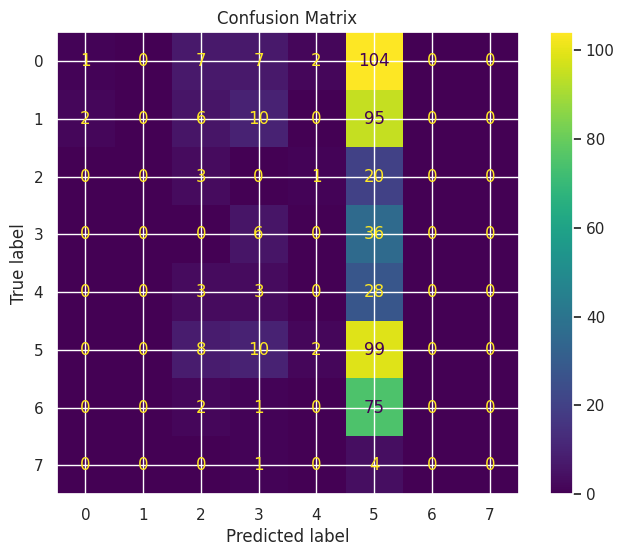

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_alpha1e-4_sgd
------------------------------
TRAIN
Accuracy: 0.3987
Precision: 0.3574
Recall: 0.3987
F1: 0.3577
Kappa: 0.2511
Error Rate: 0.6013

TEST
Accuracy: 0.2556
Precision: 0.1607
Recall: 0.2556
F1: 0.1777
Kappa: 0.0627
Error Rate: 0.7444
Gap (overfitting): 0.1431

CV
Mean: 0.2521
Std: 0.0571
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



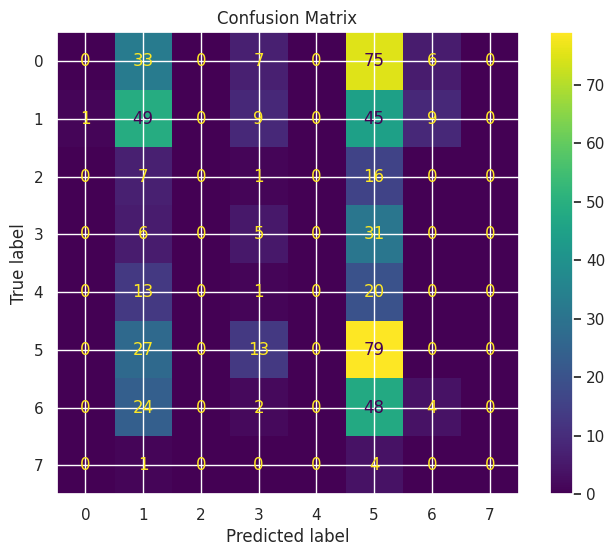

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_alpha1e-6_sgd
------------------------------
TRAIN
Accuracy: 0.3987
Precision: 0.3574
Recall: 0.3987
F1: 0.3577
Kappa: 0.2511
Error Rate: 0.6013

TEST
Accuracy: 0.2556
Precision: 0.1607
Recall: 0.2556
F1: 0.1777
Kappa: 0.0627
Error Rate: 0.7444
Gap (overfitting): 0.1431

CV
Mean: 0.2706
Std: 0.0550
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



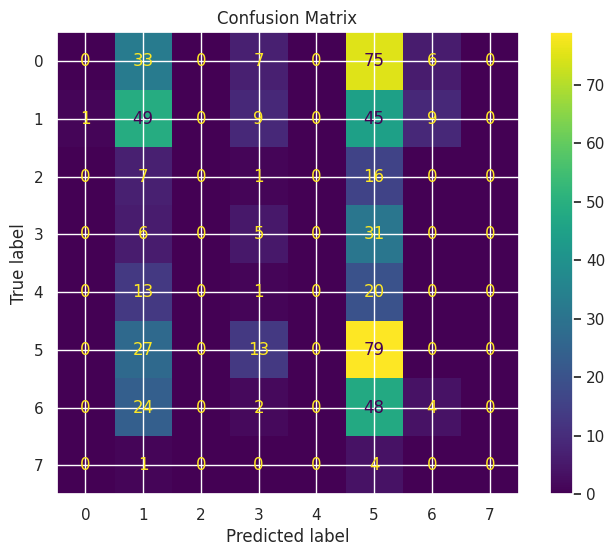

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_30_alpha1e-5_sgd
------------------------------
TRAIN
Accuracy: 0.3987
Precision: 0.3574
Recall: 0.3987
F1: 0.3577
Kappa: 0.2511
Error Rate: 0.6013

TEST
Accuracy: 0.2556
Precision: 0.1607
Recall: 0.2556
F1: 0.1777
Kappa: 0.0627
Error Rate: 0.7444
Gap (overfitting): 0.1431

CV
Mean: 0.2723
Std: 0.0538
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (30,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



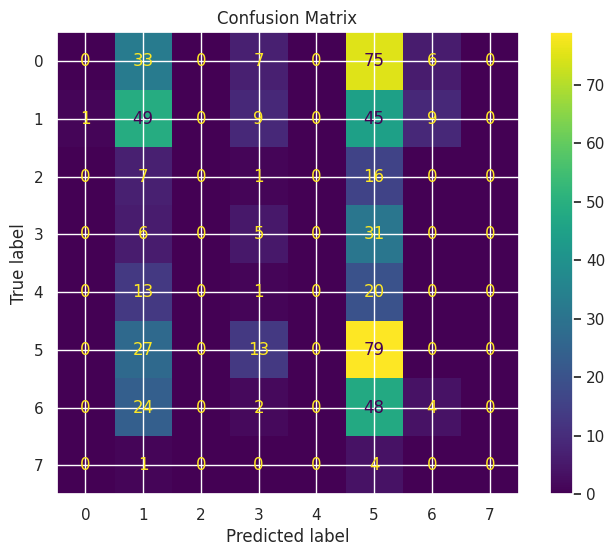

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_alpha1e-4_sgd
------------------------------
TRAIN
Accuracy: 0.4011
Precision: 0.3538
Recall: 0.4011
F1: 0.3598
Kappa: 0.2541
Error Rate: 0.5989

TEST
Accuracy: 0.2388
Precision: 0.2271
Recall: 0.2388
F1: 0.1996
Kappa: 0.0566
Error Rate: 0.7612
Gap (overfitting): 0.1623

CV
Mean: 0.2420
Std: 0.0162
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



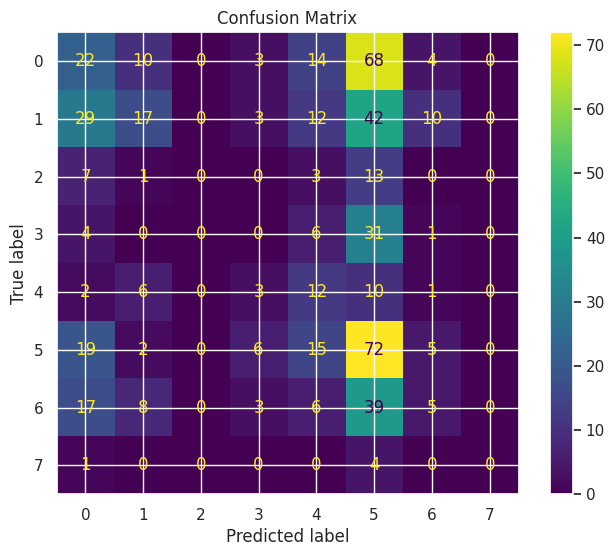

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_alpha1e-6_sgd
------------------------------
TRAIN
Accuracy: 0.4027
Precision: 0.3548
Recall: 0.4027
F1: 0.3611
Kappa: 0.2561
Error Rate: 0.5973

TEST
Accuracy: 0.2388
Precision: 0.2271
Recall: 0.2388
F1: 0.1996
Kappa: 0.0566
Error Rate: 0.7612
Gap (overfitting): 0.1639

CV
Mean: 0.2415
Std: 0.0121
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



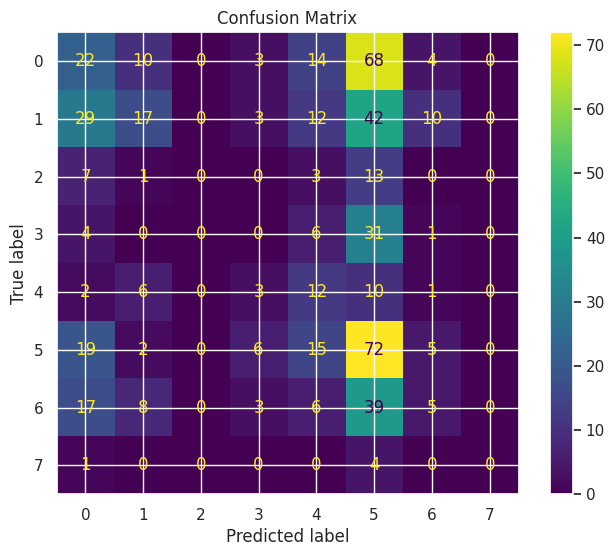

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_alpha1e-5_sgd
------------------------------
TRAIN
Accuracy: 0.4027
Precision: 0.3548
Recall: 0.4027
F1: 0.3611
Kappa: 0.2561
Error Rate: 0.5973

TEST
Accuracy: 0.2388
Precision: 0.2271
Recall: 0.2388
F1: 0.1996
Kappa: 0.0566
Error Rate: 0.7612
Gap (overfitting): 0.1639

CV
Mean: 0.2403
Std: 0.0133
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50,), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



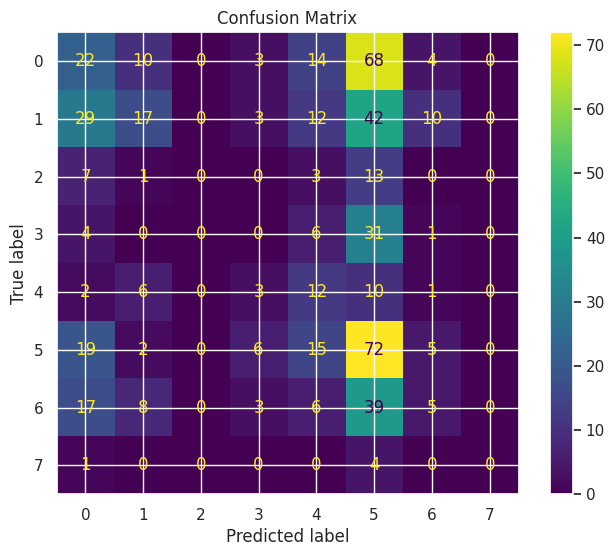

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_alpha1e-4_sgd
------------------------------
TRAIN
Accuracy: 0.4115
Precision: 0.4166
Recall: 0.4115
F1: 0.3940
Kappa: 0.2718
Error Rate: 0.5885

TEST
Accuracy: 0.1978
Precision: 0.3211
Recall: 0.1978
F1: 0.1957
Kappa: 0.0721
Error Rate: 0.8022
Gap (overfitting): 0.2138

CV
Mean: 0.2252
Std: 0.0070
------------------------------
Model params:
{'activation': 'relu', 'alpha': 0.0001, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



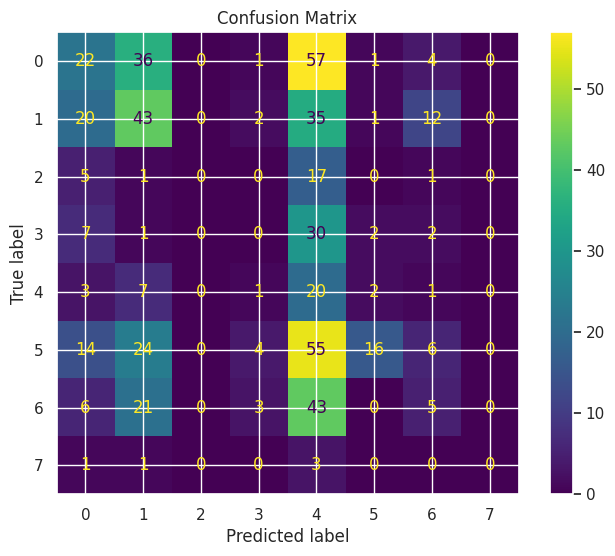

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_alpha1e-6_sgd
------------------------------
TRAIN
Accuracy: 0.4115
Precision: 0.4166
Recall: 0.4115
F1: 0.3940
Kappa: 0.2718
Error Rate: 0.5885

TEST
Accuracy: 0.1978
Precision: 0.3211
Recall: 0.1978
F1: 0.1957
Kappa: 0.0721
Error Rate: 0.8022
Gap (overfitting): 0.2138

CV
Mean: 0.2403
Std: 0.0265
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-06, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



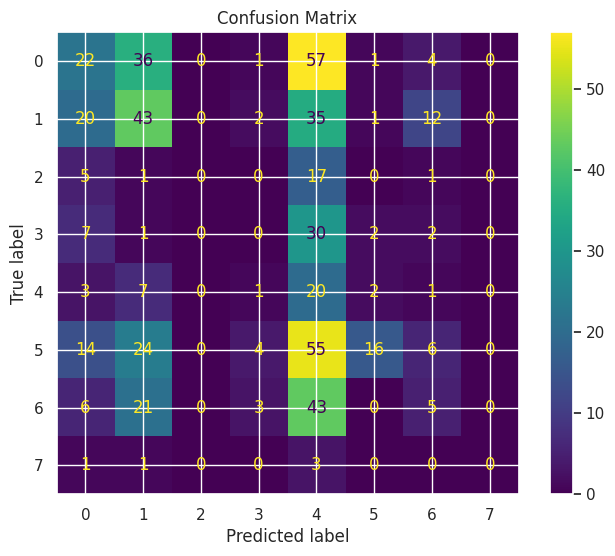

/usr/local/lib/python3.12/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but MLPClassifier was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{


Experimento: 6xN+4xS-1_05+0_95+1_1+0_9
Modelo: F3_50_25_alpha1e-5_sgd
------------------------------
TRAIN
Accuracy: 0.4115
Precision: 0.4166
Recall: 0.4115
F1: 0.3940
Kappa: 0.2718
Error Rate: 0.5885

TEST
Accuracy: 0.1978
Precision: 0.3211
Recall: 0.1978
F1: 0.1957
Kappa: 0.0721
Error Rate: 0.8022
Gap (overfitting): 0.2138

CV
Mean: 0.2403
Std: 0.0265
------------------------------
Model params:
{'activation': 'relu', 'alpha': 1e-05, 'batch_size': 'auto', 'beta_1': 0.9, 'beta_2': 0.999, 'early_stopping': False, 'epsilon': 1e-08, 'hidden_layer_sizes': (50, 25), 'learning_rate': 'adaptive', 'learning_rate_init': 0.001, 'max_fun': 15000, 'max_iter': 500, 'momentum': 0.9, 'n_iter_no_change': 10, 'nesterovs_momentum': True, 'power_t': 0.5, 'random_state': 42, 'shuffle': True, 'solver': 'sgd', 'tol': 0.0001, 'validation_fraction': 0.1, 'verbose': False, 'warm_start': False}



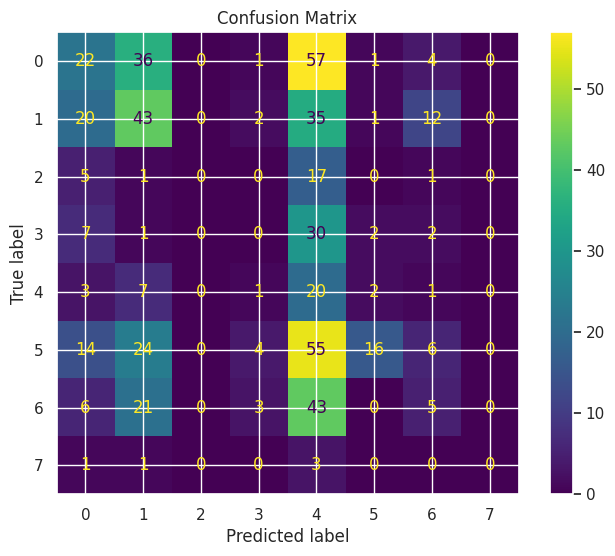

In [8]:
models_f4 = {}

models_f4['F3_30_alpha1e-4_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-4,
    random_state=42,
    max_iter=500
)

models_f4['F3_30_alpha1e-6_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-6,
    random_state=42,
    max_iter=500
)

models_f4['F3_30_alpha1e-5_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)

models_f4['F3_50_alpha1e-4_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-4,
    random_state=42,
    max_iter=500
)

models_f4['F3_50_alpha1e-6_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-6,
    random_state=42,
    max_iter=500
)

models_f4['F3_50_alpha1e-5_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)

models_f4['F3_50_25_alpha1e-4_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-4,
    random_state=42,
    max_iter=500
)

models_f4['F3_50_25_alpha1e-6_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-6,
    random_state=42,
    max_iter=500
)

models_f4['F3_50_25_alpha1e-5_adam'] = MLPClassifier(
    solver='adam',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-5,
    random_state=42,
    max_iter=500
)

models_f4['F3_30_alpha1e-4_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-4,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_30_alpha1e-6_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-6,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_30_alpha1e-5_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(30,),
    alpha=1e-5,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_50_alpha1e-4_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-4,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_50_alpha1e-6_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-6,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_50_alpha1e-5_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50,),
    alpha=1e-5,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_50_25_alpha1e-4_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-4,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_50_25_alpha1e-6_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-6,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

models_f4['F3_50_25_alpha1e-5_sgd'] = MLPClassifier(
    solver='sgd',
    activation='relu',
    hidden_layer_sizes=(50, 25),
    alpha=1e-5,
    momentum=0.9,
    learning_rate='adaptive',
    random_state=42,
    max_iter=500
)

main(models_f4, "fase_4")